## Declaración sobre el uso de Inteligencia Artificial

Durante el desarrollo e implementación del código de este notebook, **utilizamos** las siguientes herramientas de apoyo tecnológico bajo nuestra supervisión directa:

- **GitHub Copilot (GitHub, 2026):** Utilizado como asistente de autocompletado y sugerencia de fragmentos de código repetitivos en Python para el procesamiento de series de tiempo, el flujo de modelamiento F-KNN y la generación de visualizaciones comparativas.

- **Antigravity (Google DeepMind, 2026):** Empleado como asistente de ingeniería de software en la depuración del código, la modularización del estimador `FocalizedKNNImputer`, la estructuración del framework de despliegue en Streamlit y la construcción de visualizaciones interactivas con Plotly.

La validación experimental, la verificación del código, la interpretación analítica de los resultados y la autoría íntegra del contenido técnico recaen exclusivamente sobre nosotros como autores del proyecto.

> **Autores:** Gabriel Castro Benítez · Karen Daniela Torres Henao  
> Pregrado en Ciencia de Datos — Universidad Externado de Colombia, 2026.

# 03 — Comparación modular de imputadores con ajuste, validación y prueba

El cuaderno 02 divide 2018 cronológicamente en **ajuste (80 %) y validación (20 %)** y reserva 2019 como **prueba externa**. Los hiperparámetros se exploran con validación cruzada temporal dentro de ajuste; validation se usa para reportar y comparar los candidatos de cada familia. En la entrega final se amplía la búsqueda de hiperparámetros (sección 7), se reentrenan los modelos (sección 8), se evalúan una sola vez sobre la prueba de 2019 y se organizan los resultados finales (secciones 9 y 10).

Las noches con luz anómala se excluyen antes de generar las máscaras. Este cuaderno vuelve a aplicar la misma regla a los datos, verifica los índices temporales guardados dentro de los `.npz` y no vuelve a recortar las máscaras.

Los predictores se agrupan por familias meteorológicas y relaciones de dominio para reducir redundancia. Los escaladores y modelos se ajustan exclusivamente con el tramo de ajuste. La presión relativa se excluye del conjunto modelado por redundancia con la presión absoluta.

**Importante:** un R² negativo puede ser real: significa que el modelo predice peor que usar la media del valor observado para esas celdas. Agrupar predictores ayuda a controlar redundancia, pero no garantiza R² positivo.


In [4]:
%pip install scikit-learn



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [5]:
print(ARCHIVOS_TRAMOS)
print(list(ARCHIVOS_TRAMOS.keys()))

{'ajuste_2018': 'tramo_ajuste_2018.csv', 'prueba_2019': 'tramo_evaluacion_2019.csv'}
['ajuste_2018', 'prueba_2019']


In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.metrics.pairwise import nan_euclidean_distances
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler

TRAMOS = Path("../data/gold/tramos")
MASCARAS = Path("../data/gold/mascaras")
RESULTADOS_DIR = Path("../data/gold/resultados_modelos")
RESULTADOS_DIR.mkdir(parents=True, exist_ok=True)
KS = [2, 3, 5, 7, 9, 11, 13, 15, 19]

ARCHIVOS_TRAMOS = {"ajuste_2018": "tramo_ajuste_2018.csv", "prueba_2019": "tramo_evaluacion_2019.csv"}
ARCHIVOS_MASCARAS = {
    "ajuste": ("indice_ajuste_v1.csv", "mascaras_ajuste_v1.npz"),
    "validacion": ("indice_validacion_v1.csv", "mascaras_validacion_v1.npz"),
    "evaluacion": ("indice_evaluacion_v2.csv", "mascaras_evaluacion_v2.npz"),
}
LUZ = "Light(lux)"
NOCHE_INI, NOCHE_FIN = 19, 5
UMBRAL_LUZ_NOCHE = 5.0
PROPORCION_AJUSTE_2018 = 0.80

def es_noche(idx):
    return (idx.hour >= NOCHE_INI) | (idx.hour < NOCHE_FIN)

def filas_noche_anomala(df):
    noche = es_noche(df.index)
    id_noche = df.index.normalize() - pd.to_timedelta((df.index.hour < NOCHE_FIN).astype(int), unit="D")
    malas = pd.Index(id_noche[noche & df[LUZ].gt(UMBRAL_LUZ_NOCHE).fillna(False).to_numpy()]).unique()
    return noche & id_noche.isin(malas)

def limpiar_noches(df):
    return df.loc[~filas_noche_anomala(df)].copy()

raw_2018 = pd.read_csv(TRAMOS / ARCHIVOS_TRAMOS["ajuste_2018"], index_col="Time_dt", parse_dates=["Time_dt", "Time_original"])
raw_2019 = pd.read_csv(TRAMOS / ARCHIVOS_TRAMOS["prueba_2019"], index_col="Time_dt", parse_dates=["Time_dt", "Time_original"])
raw_2018.index = pd.DatetimeIndex(raw_2018.index, name="Time_dt")
raw_2019.index = pd.DatetimeIndex(raw_2019.index, name="Time_dt")
columnas_fuente = [c for c in raw_2018.columns if c != "Time_original"]
if [c for c in raw_2019.columns if c != "Time_original"] != columnas_fuente:
    raise ValueError("Columnas u orden distintos entre los archivos 2018 y 2019")
for nombre, df in [("2018", raw_2018), ("2019", raw_2019)]:
    delta = df.index.to_series().diff().dropna()
    if not (df.index.is_monotonic_increasing and df.index.is_unique and (delta == pd.Timedelta("30min")).all()):
        raise ValueError(f"Índice original irregular en {nombre}; se esperaba frecuencia de 30 minutos")

limpio_2018, limpio_2019 = limpiar_noches(raw_2018), limpiar_noches(raw_2019)
corte = int(np.floor(len(limpio_2018) * PROPORCION_AJUSTE_2018))
if corte < 1 or len(limpio_2018)-corte < 1:
    raise ValueError("No hay suficientes filas 2018 para ajuste/validación")
datos = {
    "ajuste": limpio_2018.iloc[:corte].copy(),
    "validacion": limpio_2018.iloc[corte:].copy(),
    "evaluacion": limpio_2019.copy(),  # prueba externa; conservar clave por compatibilidad
}
variables = [c for c in columnas_fuente if c != "Relative Pressure(hpa)"]
for tramo_id, df in datos.items():
    print(f"{tramo_id:12s} | {df.index.min()} -> {df.index.max()} | filas={len(df):,}")
assert datos["ajuste"].index.max() < datos["validacion"].index.min()
assert datos["validacion"].index.max() < datos["evaluacion"].index.min()


ajuste       | 2018-08-21 06:00:00 -> 2018-09-21 12:30:00 | filas=1,322
validacion   | 2018-09-21 13:00:00 -> 2018-09-30 12:00:00 | filas=331
evaluacion   | 2019-05-01 01:30:00 -> 2019-06-20 08:30:00 | filas=1,855


## 1. Escenarios de faltantes

El cuaderno 02 crea escenarios independientes por tramo, patron y porcentaje. Para cada semilla se usan los mismos ocho campos en todos los tramos y en ambos patrones; `overlap` alinea sus bloques y `disjoint` los sortea por variable.


In [7]:
def cargar_escenarios(tramo_id):
    archivo_indice, archivo_mascara = ARCHIVOS_MASCARAS[tramo_id]
    info = pd.read_csv(MASCARAS / archivo_indice)
    with np.load(MASCARAS / archivo_mascara) as archivo:
        mascaras = archivo["mascaras"]
        columnas = archivo["columnas"].astype(str).tolist()
        if "time_index" not in archivo.files:
            raise ValueError(f"{archivo_mascara} no contiene time_index; vuelve a ejecutar el cuaderno 02 corregido")
        time_index = archivo["time_index"].astype(str)
    df = datos[tramo_id]
    if len(columnas) != len(set(columnas)) or columnas != columnas_fuente:
        raise ValueError(f"Columnas/orden de máscaras no coinciden con datos fuente en {tramo_id}")
    if len(info) != len(mascaras):
        raise ValueError(f"Índice y máscaras tienen distinta cantidad de escenarios en {tramo_id}")
    if mascaras.shape[1] != len(df) or not np.array_equal(time_index, np.asarray(df.index.astype(str), dtype=str)):
        raise ValueError(f"Desalineación temporal en {tramo_id}. Ejecuta primero el cuaderno 02 corregido")
    if info["id"].tolist() != list(range(len(info))):
        raise ValueError(f"IDs de escenarios no consecutivos en {tramo_id}")
    indices_mascara = [columnas.index(c) for c in variables]
    mascaras = mascaras[:, :, indices_mascara]
    return info, mascaras

ESCENARIOS = {tramo_id: cargar_escenarios(tramo_id) for tramo_id in ARCHIVOS_MASCARAS}
for tramo_id, (info, mascaras) in ESCENARIOS.items():
    print(tramo_id, "| escenarios:", len(info), "| forma:", mascaras.shape)


ajuste | escenarios: 1150 | forma: (1150, 1322, 11)
validacion | escenarios: 790 | forma: (790, 331, 11)
evaluacion | escenarios: 1170 | forma: (1170, 1855, 11)


## 2. Esquema de evaluación temporal

La validación cruzada temporal se hace con dos folds expansivos dentro de `ajuste` (primera parte de 2018); las máscaras se generan reproduciblemente dentro del bloque futuro de cada fold. Se omiten las combinaciones de duración y porcentaje que no son realizables dentro del bloque; una duración de 7 días requiere al menos 336 filas. Los hiperparámetros se exploran y confirman solo con esos folds. Después, los candidatos se ajustan con todo `ajuste` y se reportan/comparan en `validacion` (parte final de 2018). `evaluacion` (2019) queda reservada como test y no se usa en esta entrega.


In [8]:
def crear_mapa_predictores(columnas):
    """Reglas de dominio: quitar derivados, duplicados y acumuladores colineales."""
    pos = {nombre: i for i, nombre in enumerate(columnas)}
    temp, humedad = "Outdoor Temperature(°C)", "Outdoor Humidity(%)"
    viento, rafaga = "Wind Speed(km/h)", "Gust(km/h)"
    rocío, sensacion = "DewPoint(°C)", "WindChill(°C)"
    lluvia_h, lluvia_24 = "Hour Rainfall(mm)", "24 Hour Rainfall(mm)"
    acumuladas = [c for c in (lluvia_24, "Week Rainfall(mm)", "Month Rainfall(mm)",
                              "Total Rainfall(mm)") if c in pos]
    derivados = {c for c in (rocío, sensacion) if c in pos}
    mapa = {}
    for objetivo, j in pos.items():
        if objetivo == rocío:
            permitidos = [c for c in (temp, humedad) if c in pos]
        elif objetivo == sensacion:
            permitidos = [c for c in (temp, viento) if c in pos]
        elif objetivo in acumuladas:
            permitidos = [c for c in (lluvia_h, lluvia_24, humedad) if c in pos and c != objetivo]
        else:
            # un solo representante de lluvia (la horaria); los acumulados quedan fuera
            permitidos = [c for c in columnas
                          if c != objetivo and c not in derivados and c not in acumuladas]
            if objetivo not in (viento, rafaga) and rafaga in permitidos:
                permitidos.remove(rafaga)
        mapa[j] = tuple(pos[c] for c in permitidos if c != objetivo)
    return mapa


PREDICTORES_POR_INDICE = crear_mapa_predictores(variables)
PREDICTORES_POR_OBJETIVO = {
    variables[j]: [variables[i] for i in indices]
    for j, indices in PREDICTORES_POR_INDICE.items()
}
display(pd.DataFrame([
    {"objetivo": objetivo, "predictores": ", ".join(predictores)}
    for objetivo, predictores in PREDICTORES_POR_OBJETIVO.items()
]))

# Auditoría: ningún objetivo se usa a sí mismo; la cantidad de predictores queda acotada.
assert all(obj not in preds for obj, preds in PREDICTORES_POR_OBJETIVO.items())
print("Máximo de predictores por objetivo:", max(map(len, PREDICTORES_POR_OBJETIVO.values())))


class KNNPorObjetivo(BaseEstimator, TransformerMixin):
    """KNN por objetivo; comparte distancias para evaluar varios valores de k."""

    def __init__(self, n_neighbors=5, predictor_indices=None):
        self.n_neighbors = n_neighbors
        self.predictor_indices = predictor_indices

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.n_features_in_ = X.shape[1]
        self.references_ = {}
        for j in range(self.n_features_in_):
            predictors = tuple((self.predictor_indices or {}).get(j, ()))
            observed = np.isfinite(X[:, j])
            self.references_[j] = (
                predictors,
                X[observed][:, predictors],
                X[observed, j],
                float(np.mean(X[observed, j])) if observed.any() else 0.0,
            )
        return self

    def transform_many_k(self, X, k_values):
        X = np.asarray(X, dtype=float)
        k_values = sorted({int(k) for k in k_values})
        if X.shape[1] != self.n_features_in_:
            raise ValueError("El numero de columnas no coincide con el ajuste de KNN")
        outputs = {k: X.copy() for k in k_values}

        for j, (predictors, ref_x, ref_y, fallback) in self.references_.items():
            rows = np.flatnonzero(np.isnan(X[:, j]))
            if not len(rows):
                continue
            if len(ref_y) and predictors:
                distances = nan_euclidean_distances(X[rows][:, predictors], ref_x)
            else:
                distances = np.full((len(rows), len(ref_y)), np.nan)

            n_take = min(max(k_values), len(ref_y))
            if n_take and distances.shape[1]:
                # Argpartition limita la busqueda a los vecinos que sirven para
                # el mayor k; luego se ordena solo ese bloque reducido.
                candidate_idx = np.argpartition(distances, kth=n_take - 1, axis=1)[:, :n_take]
                candidate_dist = np.take_along_axis(distances, candidate_idx, axis=1)
                order = np.argsort(candidate_dist, axis=1, kind="stable")
                candidate_idx = np.take_along_axis(candidate_idx, order, axis=1)
                candidate_dist = np.take_along_axis(candidate_dist, order, axis=1)
                candidate_y = ref_y[candidate_idx]
            else:
                candidate_dist = np.empty((len(rows), 0))
                candidate_y = np.empty((len(rows), 0))

            for k in k_values:
                use = min(k, n_take)
                if use:
                    valid = np.isfinite(candidate_dist[:, :use])
                    counts = valid.sum(axis=1)
                    totals = np.where(valid, candidate_y[:, :use], 0.0).sum(axis=1)
                    estimates = np.divide(
                        totals, counts, out=np.full(len(rows), fallback, dtype=float), where=counts > 0
                    )
                else:
                    estimates = np.full(len(rows), fallback, dtype=float)
                outputs[k][rows, j] = estimates
        return outputs

    def transform(self, X):
        return self.transform_many_k(X, [self.n_neighbors])[self.n_neighbors]


def matriz(tramo_id):
    return datos[tramo_id][variables].to_numpy(dtype=float)


def rango_de(X):
    rango = np.nanmax(X, axis=0) - np.nanmin(X, axis=0)
    rango[~np.isfinite(rango) | (rango == 0)] = 1.0
    return rango


def puntuar(X_real, mascara, X_imp, rango):
    celdas = mascara & np.isfinite(X_real) & np.isfinite(X_imp)
    columnas_validas = np.where(celdas.any(axis=0))[0]
    r2_columnas = []
    for j in columnas_validas:
        sel = celdas[:, j]
        if sel.sum() >= 2:
            r2_columnas.append(r2_score(X_real[sel, j], X_imp[sel, j]))
    if not celdas.any():
        return np.nan, np.nan
    mse = np.mean((((X_imp - X_real) / rango)[celdas]) ** 2)
    return (np.mean(r2_columnas) if r2_columnas else np.nan), mse


def crear_modelo(nombre):
    baselines = {
        "Media": "mean",
        "Mediana": "median",
        "Moda": "most_frequent",
    }
    if nombre in baselines:
        imputador = SimpleImputer(strategy=baselines[nombre], keep_empty_features=True)
    elif nombre.startswith("KNN k="):
        imputador = KNNPorObjetivo(
            n_neighbors=int(nombre.split("=")[1]),
            predictor_indices=PREDICTORES_POR_INDICE,
        )
    elif nombre == "LinearRegression":
        imputador = RegresionLinealIterativa(
            predictor_indices=PREDICTORES_POR_INDICE,
            max_iter=5,
        )
    elif nombre.startswith("F-KNN "):
        partes = dict(item.split("=") for item in nombre.split()[1:])
        fknn = FocalizedKNNImputer(
            n_neighbors=int(partes["k"]),
            correlation_threshold=float(partes["tau"]),
            n_features=int(partes["n"]),
            lags=FKNN_LAGS,
            max_lags=FKNN_MAX_LAGS,
            predictor_indices=PREDICTORES_POR_INDICE,
        )
        return Pipeline([("fknn", fknn)])
    else:
        # Registrar aqui los constructores de LinearRegression.
        raise ValueError(f"Modelo no registrado: {nombre}")
    return Pipeline([("escalar", MinMaxScaler()), ("imputar", imputador)])


def a_unidades_originales(modelo, X):
    if "fknn" in modelo.named_steps:
        return X
    return modelo.named_steps["escalar"].inverse_transform(X)


def ajustar_modelo(nombre, ids_train):
    X_fit = np.vstack([matriz(t) for t in ids_train])
    modelo = crear_modelo(nombre)
    if nombre.startswith("F-KNN "):
        # Los rezagos se reinician tanto entre tramos como después de noches eliminadas.
        longitudes = []
        for tramo_id in ids_train:
            idx = datos[tramo_id].index
            cortes = np.flatnonzero(idx.to_series().diff().gt(pd.Timedelta("30min")).to_numpy())
            limites = np.r_[0, cortes, len(idx)]
            longitudes.extend(np.diff(limites).astype(int).tolist())
        modelo.fit(X_fit, fknn__segment_lengths=longitudes)
    else:
        modelo.fit(X_fit)
    return modelo, X_fit


CV_N_SPLITS = 2
CV_SEMILLAS = tuple(range(201, 211))
CV_PATRONES = ["overlap", "disjoint"]
CV_Q = [1, 3, 6]
CV_DURACIONES = {"1h": 2, "6h": 12, "1d": 48, "3d": 144, "7d": 336}
CV_PORCENTAJES = [5, 10, 20, 30, 40, 50]
CV_TOLERANCIA = 2.0
CV_GRUPOS = {
    "interior": ["Indoor Temperature(°C)", "Indoor Humidity(%)"],
    "termohigrometro": ["Outdoor Temperature(°C)", "Outdoor Humidity(%)", "DewPoint(°C)", "WindChill(°C)"],
    "barometro": ["Relative Pressure(hpa)", "Absolute Pressure(hpa)"],
    "anemometro": ["Wind Speed(km/h)", "Gust(km/h)"],
    "pluviometro": ["Hour Rainfall(mm)"],
    "luz": ["Light(lux)"],
}

if sorted(sum(CV_GRUPOS.values(), [])) != sorted(columnas_fuente):
    raise ValueError("Los grupos de máscaras de CV no coinciden con las columnas fuente")


def inicios_bloques_cv(rng, n_filas, n_bloques, largo_bloque):
    if n_bloques < 1 or n_filas - n_bloques * largo_bloque + 1 < n_bloques:
        raise ValueError("Cantidad de bloques imposible para el bloque de validación del fold")
    inicios = np.sort(rng.choice(n_filas - n_bloques * largo_bloque + 1, size=n_bloques, replace=False))
    return inicios + np.arange(n_bloques) * largo_bloque


def generar_mascara_cv(n_filas, patron, q, largo_bloque, porcentaje, rng):
    for _ in range(300):
        grupos = list(rng.choice(list(CV_GRUPOS), size=q, replace=False))
        n_columnas = sum(len(CV_GRUPOS[grupo]) for grupo in grupos)
        n_bloques = int(round(porcentaje / 100 * n_filas * len(columnas_fuente) / (n_columnas * largo_bloque)))
        if n_bloques < 1 or n_filas - n_bloques * largo_bloque + 1 < n_bloques:
            continue
        mascara = np.zeros((n_filas, len(columnas_fuente)), dtype=bool)
        comunes = inicios_bloques_cv(rng, n_filas, n_bloques, largo_bloque)
        for grupo in grupos:
            indices_columnas = [columnas_fuente.index(columna) for columna in CV_GRUPOS[grupo]]
            inicios = comunes if patron == "overlap" else inicios_bloques_cv(rng, n_filas, n_bloques, largo_bloque)
            for inicio in inicios:
                mascara[inicio:inicio + largo_bloque, indices_columnas] = True
        if abs(mascara.mean() * 100 - porcentaje) <= CV_TOLERANCIA:
            return mascara
    return None


def escenarios_cv(tramo_id, fold_numero):
    n_filas = len(datos[tramo_id])
    indices_modelados = [columnas_fuente.index(columna) for columna in variables]
    filas, mascaras = [], []
    for patron in CV_PATRONES:
        for q in CV_Q:
            if patron == "overlap" and q == 1:
                continue
            for duracion, largo_bloque in CV_DURACIONES.items():
                for porcentaje in CV_PORCENTAJES:
                    for semilla in CV_SEMILLAS:
                        rng = np.random.default_rng([
                            int(semilla), fold_numero, CV_PATRONES.index(patron),
                            q, largo_bloque, porcentaje,
                        ])
                        mascara = generar_mascara_cv(
                            n_filas, patron, q, largo_bloque, porcentaje, rng,
                        )
                        if mascara is None:
                            continue
                        filas.append({
                            "id": len(mascaras),
                            "particion": tramo_id,
                            "patron": patron,
                            "q": q,
                            "duracion": duracion,
                            "filas_bloque": largo_bloque,
                            "pct_objetivo": porcentaje,
                            "pct_real": round(mascara.mean() * 100, 2),
                            "semilla": semilla,
                        })
                        mascaras.append(mascara[:, indices_modelados])
    if not mascaras:
        raise ValueError(f"No se pudieron generar máscaras para {tramo_id}")
    return pd.DataFrame(filas), np.stack(mascaras)


def crear_folds_temporales():
    datos_ajuste = datos["ajuste"]
    splitter = TimeSeriesSplit(n_splits=CV_N_SPLITS)
    folds = []
    for numero, (indices_train, indices_valid) in enumerate(splitter.split(datos_ajuste), start=1):
        id_train = f"ajuste_cv_{numero}"
        id_valid = f"validacion_cv_{numero}"
        datos[id_train] = datos_ajuste.iloc[indices_train].copy()
        datos[id_valid] = datos_ajuste.iloc[indices_valid].copy()
        ESCENARIOS[id_valid] = escenarios_cv(id_valid, numero)
        folds.append((f"cv_temporal_{numero}", [id_train], id_valid))
        print(
            f"CV fold {numero}: train={len(indices_train):,} filas, "
            f"validacion={len(indices_valid):,} filas, "
            f"escenarios={len(ESCENARIOS[id_valid][0]):,}"
        )
    return folds


def folds_temporales():
    """Crea folds expansivos de validación cruzada dentro de ajuste 2018."""
    return crear_folds_temporales()

FOLDS = folds_temporales()
for fold, ids_train, id_valid in FOLDS:
    print(f"fold {fold}: train={ids_train} | bloque futuro={id_valid}")


def evaluar_en_tramo(nombre, ids_train, id_eval, fold=None, semillas=None):
    modelo, X_fit = ajustar_modelo(nombre, ids_train)
    X_real = matriz(id_eval)
    rango = rango_de(X_fit)
    info, mascaras = ESCENARIOS[id_eval]
    if semillas is not None:
        info = info[info["semilla"].isin(semillas)]
    filas = []
    for escenario in info.itertuples(index=False):
        mascara = mascaras[int(escenario.id)]
        X_oculto = X_real.copy()
        X_oculto[mascara] = np.nan
        X_imp = a_unidades_originales(modelo, modelo.transform(X_oculto))
        r2, mse = puntuar(X_real, mascara, X_imp, rango)
        registro = {
            "tramo_id": id_eval,
            "metodo": nombre,
            "patron": escenario.patron,
            "pct_objetivo": escenario.pct_objetivo,
            "pct_real": 100 * np.count_nonzero(mascara & np.isfinite(X_real)) / np.isfinite(X_real).sum(),
            "n_variables": int(mascara.any(axis=0).sum()),
            "duracion": escenario.duracion,
            "semilla": escenario.semilla,
            "R2": r2,
            "MSE": mse,
        }
        if fold is not None:
            registro["fold"] = fold
        filas.append(registro)
    return pd.DataFrame(filas)


def evaluar_knn_varios_k(ids_train, id_eval, k_values, fold=None):
    """Evalua varios k compartiendo las distancias de cada mascara y objetivo."""
    X_fit = np.vstack([matriz(t) for t in ids_train])
    scaler = MinMaxScaler().fit(X_fit)
    X_fit_scaled = scaler.transform(X_fit)
    imputador = KNNPorObjetivo(
        n_neighbors=max(k_values), predictor_indices=PREDICTORES_POR_INDICE
    ).fit(X_fit_scaled)

    X_real = matriz(id_eval)
    rango = rango_de(X_fit)
    info, mascaras = ESCENARIOS[id_eval]
    filas = []
    total = len(info)
    for numero, escenario in enumerate(info.itertuples(index=False), start=1):
        mascara = mascaras[int(escenario.id)]
        X_oculto = X_real.copy()
        X_oculto[mascara] = np.nan
        predicciones = imputador.transform_many_k(scaler.transform(X_oculto), k_values)
        for k, X_imp_scaled in predicciones.items():
            X_imp = scaler.inverse_transform(X_imp_scaled)
            r2, mse = puntuar(X_real, mascara, X_imp, rango)
            registro = {
                "tramo_id": id_eval,
                "metodo": f"KNN k={k}",
                "patron": escenario.patron,
                "pct_objetivo": escenario.pct_objetivo,
                "pct_real": 100 * np.count_nonzero(mascara & np.isfinite(X_real)) / np.isfinite(X_real).sum(),
                "n_variables": int(mascara.any(axis=0).sum()),
                "duracion": escenario.duracion,
                "semilla": escenario.semilla,
                "R2": r2,
                "MSE": mse,
            }
            if fold is not None:
                registro["fold"] = fold
            filas.append(registro)
        if numero % 10 == 0 or numero == total:
            print(f"KNN {id_eval}: escenario {numero}/{total}")
    return pd.DataFrame(filas)


def guardar_resultados(df, nombre):
    if df is not None and not df.empty:
        df.to_csv(RESULTADOS_DIR / f"{nombre}.csv", index=False)
        print("Guardado:", RESULTADOS_DIR / f"{nombre}.csv", "| filas:", len(df))


COLUMNAS_RESULTADOS = [
    "tramo_id", "metodo", "patron", "pct_objetivo", "pct_real",
    "n_variables", "duracion", "semilla", "R2", "MSE",
]


,objetivo,predictores
0,Indoor Temperature(°C),"Indoor Humidity(%), Outdoor Temperature(°C), O..."
1,Indoor Humidity(%),"Indoor Temperature(°C), Outdoor Temperature(°C..."
2,Outdoor Temperature(°C),"Indoor Temperature(°C), Indoor Humidity(%), Ou..."
3,Outdoor Humidity(%),"Indoor Temperature(°C), Indoor Humidity(%), Ou..."
4,Absolute Pressure(hpa),"Indoor Temperature(°C), Indoor Humidity(%), Ou..."
5,Wind Speed(km/h),"Indoor Temperature(°C), Indoor Humidity(%), Ou..."
6,Gust(km/h),"Indoor Temperature(°C), Indoor Humidity(%), Ou..."
7,DewPoint(°C),"Outdoor Temperature(°C), Outdoor Humidity(%)"
8,WindChill(°C),"Outdoor Temperature(°C), Wind Speed(km/h)"
9,Hour Rainfall(mm),"Indoor Temperature(°C), Indoor Humidity(%), Ou..."


Máximo de predictores por objetivo: 8
CV fold 1: train=442 filas, validacion=440 filas, escenarios=910
CV fold 2: train=882 filas, validacion=440 filas, escenarios=910
fold cv_temporal_1: train=['ajuste_cv_1'] | bloque futuro=validacion_cv_1
fold cv_temporal_2: train=['ajuste_cv_2'] | bloque futuro=validacion_cv_2


## 3. Líneas base: media, mediana y moda

Las líneas base no usan predictores; cada una aprende una estadística por variable exclusivamente con ajuste 2018. Se aplican las mismas máscaras de evaluación 2019 que a los demás métodos, para que la comparación sea equivalente. El R² de la línea base también puede ser negativo y no debe forzarse a positivo.


In [9]:
NOMBRES_BASELINE = ["Media", "Mediana", "Moda"]
partes_cv_baseline = []
for fold, ids_train, id_valid in FOLDS:
    for nombre in NOMBRES_BASELINE:
        partes_cv_baseline.append(evaluar_en_tramo(nombre, ids_train, id_valid, fold=fold))
resultados_cv_baseline = pd.concat(partes_cv_baseline, ignore_index=True)

resultados_val_baseline = pd.concat(
    [evaluar_en_tramo(nombre, ["ajuste"], "validacion") for nombre in NOMBRES_BASELINE],
    ignore_index=True,
)
guardar_resultados(resultados_cv_baseline, "baseline_train_cv")
guardar_resultados(resultados_val_baseline, "baseline_validation_2018")
display(resultados_val_baseline.groupby(["metodo", "patron", "pct_objetivo"])[["R2", "MSE"]].mean().round(4))


Guardado: ../data/gold/resultados_modelos/baseline_train_cv.csv | filas: 5460
Guardado: ../data/gold/resultados_modelos/baseline_validation_2018.csv | filas: 2370


R2     MSE
metodo  patron   pct_objetivo                
Media   disjoint 5            -1.0257  0.0290
                 10           -0.1715  0.0333
                 20           -0.1019  0.0341
                 30           -0.0586  0.0340
                 40           -0.0636  0.0343
                 50           -0.0495  0.0337
        overlap  5            -3.4011  0.0325
                 10           -0.2606  0.0294
                 20           -0.1466  0.0323
                 30           -0.1020  0.0302
                 40           -0.0678  0.0330
                 50           -0.0693  0.0342
Mediana disjoint 5            -0.6758  0.0312
                 10           -0.1810  0.0363
                 20           -0.1262  0.0371
                 30           -0.1143  0.0367
                 40           -0.1111  0.0367
                 50           -0.1050  0.0363
        overlap  5            -2.3147  0.0352
                 10           -0.1839  0.0312
                 20           -0.1477  0.0348
                 30           -0.1247  0.0327
                 40           -0.1039  0.0351
                 50           -0.1091  0.0368
Moda    disjoint 5            -0.9455  0.0400
                 10           -0.5679  0.0503
                 20           -0.6061  0.0574
                 30           -0.5911  0.0567
                 40           -0.5598  0.0550
                 50           -0.5608  0.0553
        overlap  5            -2.4240  0.0494
                 10           -0.5964  0.0444
                 20           -0.5166  0.0486
                 30           -0.5164  0.0467
                 40           -0.5458  0.0529
                 50           -0.5469  0.0555

## 4. KNN: evaluacion de todos los valores de `k`

Se prueban los nueve valores de `k` con escenarios, semillas y patrones en los dos folds temporales dentro de `ajuste` 2018. Para acelerar la busqueda, por cada escenario y variable objetivo se calculan las distancias y se ordenan los vecinos una sola vez hasta el `k` maximo; las predicciones para los demas valores de `k` reutilizan ese orden. El mejor `k` se selecciona por el promedio out-of-fold, con MSE como desempate, y su resultado se reporta en `validacion` 2018.

Cada objetivo usa solo sus predictores permitidos al calcular distancias.


In [10]:
partes_cv_knn = []
for fold, ids_train, id_valid in FOLDS:
    partes_cv_knn.append(evaluar_knn_varios_k(ids_train, id_valid, KS, fold=fold))
resultados_cv_knn = pd.concat(partes_cv_knn, ignore_index=True)
guardar_resultados(resultados_cv_knn, "knn_train_cv")

tabla_k = (
    resultados_cv_knn
    .assign(k=lambda d: d["metodo"].str.replace("KNN k=", "", regex=False).astype(int))
    .groupby("k")
    .agg(R2_medio=("R2", "mean"), R2_sd=("R2", "std"), MSE_medio=("MSE", "mean"), escenarios=("MSE", "count"))
    .reset_index())
# Selección equilibrada: ranking conjunto de R² (más alto) y MSE normalizado (más bajo).
# Así no se elige k por una sola métrica; el desempate favorece mayor R² y menor MSE.
tabla_k["rango_R2"] = tabla_k["R2_medio"].rank(ascending=False, method="average")
tabla_k["rango_MSE"] = tabla_k["MSE_medio"].rank(ascending=True, method="average")
tabla_k["rango_balanceado"] = (tabla_k["rango_R2"] + tabla_k["rango_MSE"]) / 2
tabla_k = tabla_k.sort_values(["rango_balanceado", "R2_medio", "MSE_medio"], ascending=[True, False, True]).reset_index(drop=True)
display(tabla_k.round(4))

KNN validacion_cv_1: escenario 10/910
KNN validacion_cv_1: escenario 20/910
KNN validacion_cv_1: escenario 30/910
KNN validacion_cv_1: escenario 40/910
KNN validacion_cv_1: escenario 50/910
KNN validacion_cv_1: escenario 60/910
KNN validacion_cv_1: escenario 70/910
KNN validacion_cv_1: escenario 80/910
KNN validacion_cv_1: escenario 90/910
KNN validacion_cv_1: escenario 100/910
KNN validacion_cv_1: escenario 110/910
KNN validacion_cv_1: escenario 120/910
KNN validacion_cv_1: escenario 130/910
KNN validacion_cv_1: escenario 140/910
KNN validacion_cv_1: escenario 150/910
KNN validacion_cv_1: escenario 160/910
KNN validacion_cv_1: escenario 170/910
KNN validacion_cv_1: escenario 180/910
KNN validacion_cv_1: escenario 190/910
KNN validacion_cv_1: escenario 200/910
KNN validacion_cv_1: escenario 210/910
KNN validacion_cv_1: escenario 220/910
KNN validacion_cv_1: escenario 230/910
KNN validacion_cv_1: escenario 240/910
KNN validacion_cv_1: escenario 250/910
KNN validacion_cv_1: escenario 260

,k,R2_medio,R2_sd,MSE_medio,escenarios,rango_R2,rango_MSE,rango_balanceado
0,19,0.1029,0.4719,0.0325,1820,1.0,1.0,1.0
1,15,0.0999,0.4767,0.0325,1820,2.0,2.0,2.0
2,13,0.0962,0.4843,0.0326,1820,3.0,3.0,3.0
3,11,0.0904,0.4909,0.0327,1820,4.0,4.0,4.0
4,9,0.0842,0.5016,0.0329,1820,5.0,5.0,5.0
5,7,0.0683,0.5346,0.0332,1820,6.0,6.0,6.0
6,5,0.0386,0.5677,0.0340,1820,7.0,7.0,7.0
7,3,-0.0104,0.6597,0.0353,1820,8.0,8.0,8.0
8,2,-0.0580,0.7493,0.0366,1820,9.0,9.0,9.0


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


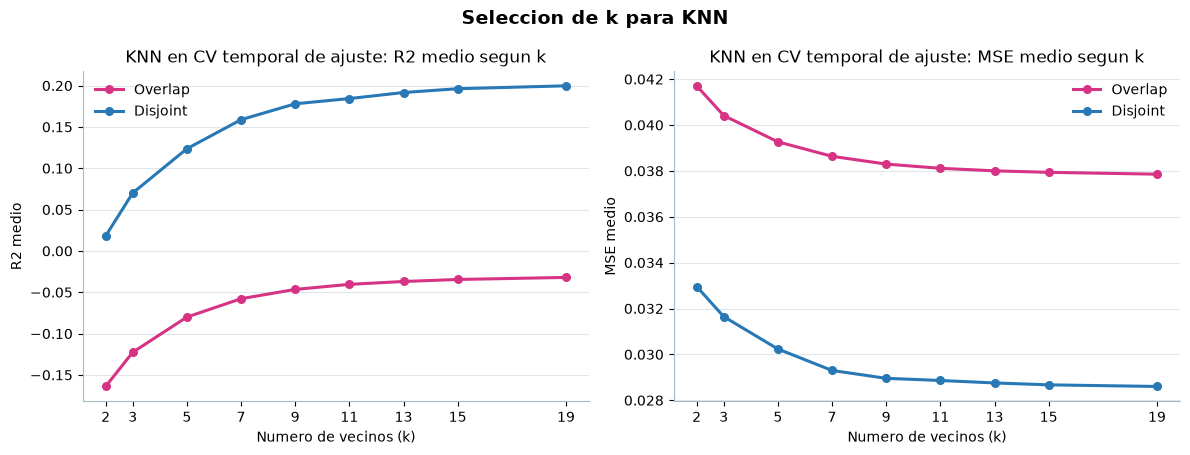

In [11]:
df_knn_grafica = resultados_cv_knn.copy()
ks_grafica = sorted(df_knn_grafica["metodo"].str.extract(r"k=(\d+)")[0].dropna().astype(int).unique())
df_knn_grafica["k"] = df_knn_grafica["metodo"].str.extract(r"k=(\d+)")[0].astype(int)
paleta_patrones = {"overlap": "#D63384", "disjoint": "#2878B5"}
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.6), sharex=True)
for ax, (metrica, etiqueta) in zip(ejes, [("R2", "R2 medio"), ("MSE", "MSE medio")]):
    for patron in ("overlap", "disjoint"):
        curva = (df_knn_grafica[df_knn_grafica["patron"] == patron]
                 .groupby("k")[metrica].mean().reindex(ks_grafica))
        ax.plot(ks_grafica, curva, marker="o", markersize=5.5, linewidth=2.2,
                color=paleta_patrones[patron], label=patron.capitalize())
    ax.set(xlabel="Numero de vecinos (k)", ylabel=etiqueta, title=f"KNN en CV temporal de ajuste: {etiqueta} segun k")
    ax.set_xticks(ks_grafica)
    ax.grid(axis="y", color="#D9E1E8", linewidth=0.8, alpha=0.8)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#AAB7C4")
    ax.spines["bottom"].set_color("#AAB7C4")
    ax.legend(frameon=False, loc="best")
fig.suptitle("Seleccion de k para KNN", fontsize=14, fontweight="semibold")
fig.tight_layout()
plt.show()

In [12]:
K_ELEGIDO = int(tabla_k.iloc[0]["k"])
NOMBRE_KNN_ELEGIDO = f"KNN k={K_ELEGIDO}"
K_ELEGIDO_EQ = 13
NOMBRE_KNN_ELEGIDO_EQ = f"KNN k={K_ELEGIDO_EQ}"

print("k seleccionado por CV temporal dentro de ajuste:", K_ELEGIDO_EQ)

resultados_val_knn = evaluar_en_tramo(NOMBRE_KNN_ELEGIDO_EQ, ["ajuste"], "validacion")
guardar_resultados(resultados_val_knn, "knn_validation_2018")
display(resultados_val_knn.groupby(["metodo", "patron", "pct_objetivo"])[["R2", "MSE"]].mean().round(4))

k seleccionado por CV temporal dentro de ajuste: 13
Guardado: ../data/gold/resultados_modelos/knn_validation_2018.csv | filas: 790


R2     MSE
metodo   patron   pct_objetivo                
KNN k=13 disjoint 5            -0.0928  0.0152
                  10            0.2839  0.0169
                  20            0.3165  0.0163
                  30            0.3478  0.0173
                  40            0.2974  0.0195
                  50            0.2525  0.0209
         overlap  5            -2.8368  0.0247
                  10           -0.0382  0.0221
                  20            0.1113  0.0234
                  30            0.0942  0.0232
                  40            0.1187  0.0251
                  50            0.1217  0.0256

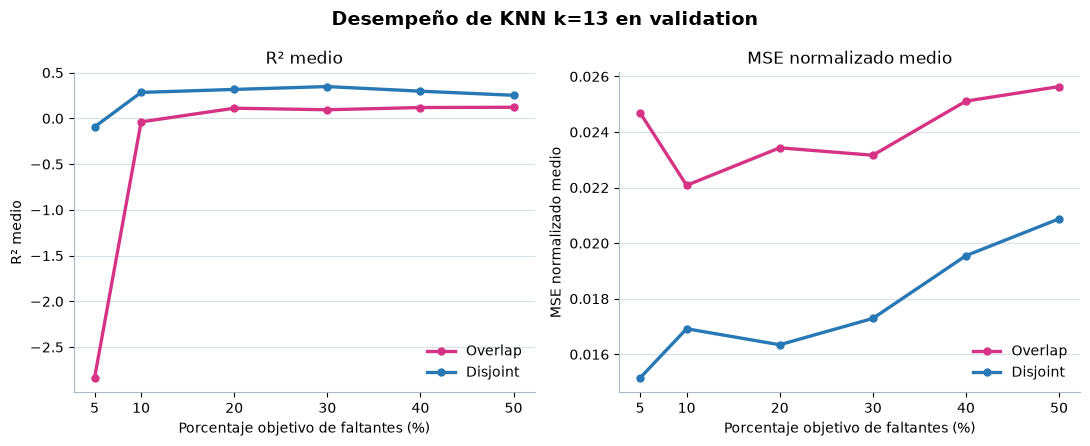

In [13]:
# KNN elegido: desempeño en validation por patrón de faltantes
knn_plot = resultados_val_knn.copy()

colores = {
    "overlap": "#D63384",
    "disjoint": "#2878B5",
}

fig, ejes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True)

for ax, metrica, etiqueta in zip(
    ejes,
    ["R2", "MSE"],
    ["R² medio", "MSE normalizado medio"],):
    for patron in ["overlap", "disjoint"]:
        sub = knn_plot[knn_plot["patron"] == patron]

        curva = (
            sub.groupby("pct_objetivo")[metrica]
            .mean()
            .sort_index()
        )

        ax.plot(
            curva.index,
            curva.values,
            marker="o",
            linewidth=2.4,
            markersize=5,
            color=colores[patron],
            label=patron.capitalize(),
        )

    ax.set_title(etiqueta)
    ax.set_xlabel("Porcentaje objetivo de faltantes (%)")
    ax.set_xticks(sorted(knn_plot["pct_objetivo"].unique()))
    ax.grid(axis="y", color="#D9E1E8", linewidth=0.8)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#AAB7C4")
    ax.spines["bottom"].set_color("#AAB7C4")
    ax.legend(frameon=False)

ejes[0].set_ylabel("R² medio")
ejes[1].set_ylabel("MSE normalizado medio")

fig.suptitle(
    f"Desempeño de {knn_plot['metodo'].iloc[0]} en validation",
    fontsize=14,
    fontweight="semibold",
)
fig.tight_layout()
plt.show()

Pesos uniformes vs pesos por distancia

In [14]:
# ===== BLOQUE 1: KNN con pesos uniformes vs por distancia (validación cruzada) =====
class KNNPorObjetivoPeso(KNNPorObjetivo):
    """Igual que KNNPorObjetivo, pero permite pesar a los vecinos por 1/distancia."""

    def __init__(self, n_neighbors=5, predictor_indices=None, pesos="uniforme"):
        super().__init__(n_neighbors=n_neighbors, predictor_indices=predictor_indices)
        self.pesos = pesos

    def transform_many_k(self, X, k_values):
        X = np.asarray(X, dtype=float)
        k_values = sorted({int(k) for k in k_values})
        outputs = {k: X.copy() for k in k_values}
        for j, (predictors, ref_x, ref_y, fallback) in self.references_.items():
            rows = np.flatnonzero(np.isnan(X[:, j]))
            if not len(rows):
                continue
            if len(ref_y) and predictors:
                distances = nan_euclidean_distances(X[rows][:, predictors], ref_x)
            else:
                distances = np.full((len(rows), len(ref_y)), np.nan)
            n_take = min(max(k_values), len(ref_y))
            if n_take and distances.shape[1]:
                idx = np.argpartition(distances, kth=n_take - 1, axis=1)[:, :n_take]
                dist = np.take_along_axis(distances, idx, axis=1)
                orden = np.argsort(dist, axis=1, kind="stable")
                idx = np.take_along_axis(idx, orden, axis=1)
                dist = np.take_along_axis(dist, orden, axis=1)
                y_vec = ref_y[idx]
            else:
                dist = np.empty((len(rows), 0))
                y_vec = np.empty((len(rows), 0))
            for k in k_values:
                use = min(k, n_take)
                if use:
                    d = dist[:, :use]
                    valido = np.isfinite(d)
                    if self.pesos == "distancia":
                        w = np.where(valido, 1.0 / (np.where(valido, d, 0.0) + 1e-6), 0.0)
                    else:
                        w = valido.astype(float)
                    w_total = w.sum(axis=1)
                    suma = (w * np.where(valido, y_vec[:, :use], 0.0)).sum(axis=1)
                    est = np.divide(suma, w_total, out=np.full(len(rows), fallback, dtype=float),
                                    where=w_total > 0)
                else:
                    est = np.full(len(rows), fallback, dtype=float)
                outputs[k][rows, j] = est
        return outputs


def evaluar_knn_pesos(ids_train, id_eval, k_values, pesos, fold=None):
    X_fit = np.vstack([matriz(t) for t in ids_train])
    scaler = MinMaxScaler().fit(X_fit)
    imputador = KNNPorObjetivoPeso(
        n_neighbors=max(k_values), predictor_indices=PREDICTORES_POR_INDICE, pesos=pesos
    ).fit(scaler.transform(X_fit))
    X_real = matriz(id_eval)
    rango = rango_de(X_fit)
    info, mascaras = ESCENARIOS[id_eval]
    filas = []
    for esc in info.itertuples(index=False):
        mascara = mascaras[int(esc.id)]
        X_oculto = X_real.copy()
        X_oculto[mascara] = np.nan
        preds = imputador.transform_many_k(scaler.transform(X_oculto), k_values)
        for k, X_imp_s in preds.items():
            r2, mse = puntuar(X_real, mascara, scaler.inverse_transform(X_imp_s), rango)
            reg = {"pesos": pesos, "k": k, "patron": esc.patron,
                   "pct_objetivo": esc.pct_objetivo, "semilla": esc.semilla, "R2": r2, "MSE": mse}
            if fold is not None:
                reg["fold"] = fold
            filas.append(reg)
    return pd.DataFrame(filas)


partes = []
for pesos in ["uniforme", "distancia"]:
    for fold, ids_train, id_valid in FOLDS:
        partes.append(evaluar_knn_pesos(ids_train, id_valid, KS, pesos, fold=fold))
cv_pesos = pd.concat(partes, ignore_index=True)
guardar_resultados(cv_pesos, "knn_pesos_train_cv")

tabla_pesos = (cv_pesos.groupby(["pesos", "k"])
               .agg(R2_medio=("R2", "mean"), R2_sd=("R2", "std"), MSE_medio=("MSE", "mean"))
               .round(4).reset_index().sort_values("R2_medio", ascending=False))
display(tabla_pesos)
print("Con k=13:")
display(tabla_pesos[tabla_pesos["k"] == 13])

Guardado: ../data/gold/resultados_modelos/knn_pesos_train_cv.csv | filas: 32760


,pesos,k,R2_medio,R2_sd,MSE_medio
17,uniforme,19,0.1029,0.4719,0.0325
16,uniforme,15,0.0999,0.4767,0.0325
15,uniforme,13,0.0962,0.4843,0.0326
8,distancia,19,0.0951,0.4785,0.0328
7,distancia,15,0.0909,0.4845,0.0329
14,uniforme,11,0.0904,0.4909,0.0327
6,distancia,13,0.0866,0.4927,0.0330
13,uniforme,9,0.0842,0.5016,0.0329
5,distancia,11,0.0809,0.5001,0.0331
4,distancia,9,0.0746,0.5121,0.0332


Con k=13:


,pesos,k,R2_medio,R2_sd,MSE_medio
15,uniforme,13,0.0962,0.4843,0.0326
6,distancia,13,0.0866,0.4927,0.0330


## 5. Regresion lineal iterativa por objetivo

Se ajusta una regresion lineal independiente para cada columna, respetando `PREDICTORES_POR_OBJETIVO`. Se inicializan los faltantes con medias aprendidas del entrenamiento y se repiten cinco rondas de modelos por objetivo. En cada ronda, las regresiones se ajustan solo con filas donde el objetivo de entrenamiento esta observado; las predicciones actualizan unicamente los faltantes. En la prueba 2019 se aplican los modelos ya ajustados, sin volver a entrenar.

La lista de predictores excluye variables derivadas de otras (`WindChill` y `DewPoint`) y redundancias de viento; sus propias imputaciones se basan en sus variables de origen. La presion relativa queda fuera del conjunto modelado, mientras ambas columnas originales permanecen en los archivos fuente.


In [15]:
from sklearn.linear_model import Ridge

class RegresionLinealIterativa(BaseEstimator, TransformerMixin):
    """Imputacion chained con regresion Ridge, poda por VIF y recorte al rango de train."""

    def __init__(self, predictor_indices=None, max_iter=5, vif_max=10.0, alpha=1.0):
        self.predictor_indices = predictor_indices
        self.max_iter = max_iter
        self.vif_max = vif_max
        self.alpha = alpha

    def _podar_por_vif(self, X, predictors):
        """Poda predictores redundantes; el umbral VIF se calcula por regresión auxiliar."""
        preds = list(dict.fromkeys(predictors))
        while len(preds) > 1:
            Xp = np.asarray(X[:, preds], dtype=float)
            Xp = Xp[np.isfinite(Xp).all(axis=1)]
            if len(Xp) < max(30, len(preds) + 2):
                break
            variabilidad = np.nanstd(Xp, axis=0)
            constantes = variabilidad <= np.finfo(float).eps
            if constantes.any():
                preds = [p for p, constante in zip(preds, constantes) if not constante]
                continue
            corr = np.corrcoef(Xp, rowvar=False)
            # Identifica redundancia extrema incluso cuando la matriz es singular.
            upper = np.triu(np.abs(corr), k=1)
            if upper.size and np.nanmax(upper) >= 0.995:
                a, b = np.unravel_index(np.nanargmax(upper), upper.shape)
                # Conserva el primer predictor de dominio y elimina el redundante.
                preds.pop(b)
                continue
            vif = []
            for k in range(Xp.shape[1]):
                y_aux = Xp[:, k]
                X_aux = np.delete(Xp, k, axis=1)
                r2_aux = LinearRegression().fit(X_aux, y_aux).score(X_aux, y_aux)
                vif.append(1.0 / max(1.0 - min(float(r2_aux), 1.0 - 1e-12), 1e-12))
            if max(vif) <= self.vif_max:
                break
            preds.pop(int(np.argmax(vif)))
        return tuple(preds)

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.n_features_in_ = X.shape[1]
        self.missing_fit_ = np.isnan(X)
        self.initial_values_ = np.nanmean(X, axis=0)
        self.initial_values_[~np.isfinite(self.initial_values_)] = 0.0
        self.min_ = np.nan_to_num(np.nanmin(X, axis=0), nan=-np.inf)
        self.max_ = np.nan_to_num(np.nanmax(X, axis=0), nan=np.inf)
        state = np.where(self.missing_fit_, self.initial_values_[None, :], X)
        self.models_by_iteration_ = []
        self.predictors_ = {
            j: self._podar_por_vif(X, [i for i in (self.predictor_indices or {}).get(j, ()) if i != j])
            for j in range(self.n_features_in_)
        }
        filas_faltantes = [np.flatnonzero(self.missing_fit_[:, j]) for j in range(self.n_features_in_)]
        for _ in range(self.max_iter):
            models = {}
            for j, predictors in self.predictors_.items():
                observed = np.isfinite(X[:, j])
                if not predictors or observed.sum() < 2:
                    continue
                model = Ridge(alpha=self.alpha).fit(state[observed][:, predictors], X[observed, j])
                coef, b = model.coef_.copy(), float(model.intercept_)
                models[j] = (coef, b)   # se guarda como arrays: prediccion manual, mas rapida
                rows = filas_faltantes[j]
                if rows.size:
                    state[rows, j] = np.clip(state[np.ix_(rows, predictors)] @ coef + b,
                                             self.min_[j], self.max_[j])
            self.models_by_iteration_.append(models)
        return self

    def transform(self, X):
        X = np.asarray(X, dtype=float)
        if X.shape[1] != self.n_features_in_:
            raise ValueError("El numero de columnas no coincide con el ajuste")
        missing = np.isnan(X)
        state = np.where(missing, self.initial_values_[None, :], X)
        filas = [np.flatnonzero(missing[:, j]) for j in range(self.n_features_in_)]  # una sola vez
        for models in self.models_by_iteration_:
            for j, (coef, b) in models.items():
                rows = filas[j]
                if rows.size:
                    state[rows, j] = np.clip(state[np.ix_(rows, self.predictors_[j])] @ coef + b,
                                             self.min_[j], self.max_[j])
        return state

NOMBRE_LINEAR = "LinearRegression"
partes_cv_linear = []
for fold, ids_train, id_valid in FOLDS:
    partes_cv_linear.append(evaluar_en_tramo(NOMBRE_LINEAR, ids_train, id_valid, fold=fold))
resultados_cv_linear = pd.concat(partes_cv_linear, ignore_index=True)

resultados_val_linear = evaluar_en_tramo(NOMBRE_LINEAR, ["ajuste"], "validacion")
guardar_resultados(resultados_cv_linear, "linear_regression_train_cv")
guardar_resultados(resultados_val_linear, "linear_regression_validation_2018")
display(resultados_val_linear.groupby(["metodo", "patron", "pct_objetivo"])[["R2", "MSE"]].mean().round(4))


Guardado: ../data/gold/resultados_modelos/linear_regression_train_cv.csv | filas: 1820
Guardado: ../data/gold/resultados_modelos/linear_regression_validation_2018.csv | filas: 790


R2     MSE
metodo           patron   pct_objetivo                
LinearRegression disjoint 5            -0.2700  0.0150
                          10            0.2290  0.0166
                          20            0.3124  0.0148
                          30            0.3654  0.0162
                          40            0.2829  0.0200
                          50            0.2364  0.0216
                 overlap  5            -2.9490  0.0262
                          10           -0.1246  0.0225
                          20            0.0172  0.0245
                          30            0.0637  0.0244
                          40            0.0837  0.0264
                          50            0.1147  0.0259

In [16]:
modelo_lin, _ = ajustar_modelo("LinearRegression", ["ajuste"])
imp = modelo_lin.named_steps["imputar"]
display(pd.DataFrame({variables[j]: [", ".join(variables[i] for i in p)] for j, p in imp.predictors_.items()}, index=["predictores"]).T)

,predictores
Indoor Temperature(°C),"Indoor Humidity(%), Outdoor Temperature(°C), A..."
Indoor Humidity(%),"Indoor Temperature(°C), Outdoor Humidity(%), A..."
Outdoor Temperature(°C),"Indoor Temperature(°C), Indoor Humidity(%), Ou..."
Outdoor Humidity(%),"Indoor Temperature(°C), Indoor Humidity(%), Ou..."
Absolute Pressure(hpa),"Indoor Temperature(°C), Indoor Humidity(%), Ou..."
Wind Speed(km/h),"Indoor Temperature(°C), Indoor Humidity(%), Ou..."
Gust(km/h),"Indoor Temperature(°C), Indoor Humidity(%), Ou..."
DewPoint(°C),Outdoor Humidity(%)
WindChill(°C),"Outdoor Temperature(°C), Wind Speed(km/h)"
Hour Rainfall(mm),"Indoor Temperature(°C), Indoor Humidity(%), Ou..."


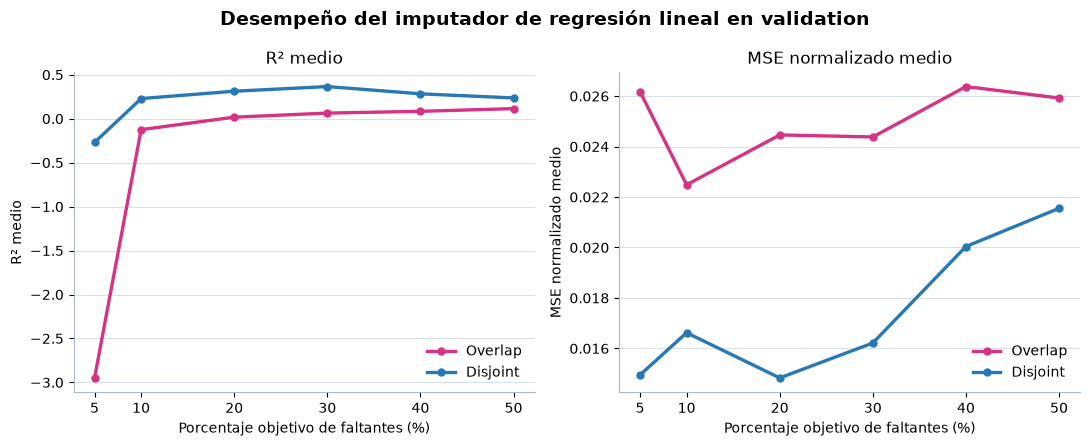

In [17]:
# Regresión lineal: desempeño en validation por patrón de faltantes
linear_plot = resultados_val_linear.copy()

colores = {
    "overlap": "#D63384",
    "disjoint": "#2878B5",}

fig, ejes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True)

for ax, metrica, etiqueta in zip(
    ejes,
    ["R2", "MSE"],
    ["R² medio", "MSE normalizado medio"],):
    for patron in ["overlap", "disjoint"]:
        sub = linear_plot[linear_plot["patron"] == patron]

        curva = (
            sub.groupby("pct_objetivo")[metrica]
            .mean()
            .sort_index()
        )

        ax.plot(
            curva.index,
            curva.values,
            marker="o",
            linewidth=2.4,
            markersize=5,
            color=colores[patron],
            label=patron.capitalize(),
        )

    ax.set_title(etiqueta)
    ax.set_xlabel("Porcentaje objetivo de faltantes (%)")
    ax.set_xticks(sorted(linear_plot["pct_objetivo"].unique()))
    ax.grid(axis="y", color="#D9E1E8", linewidth=0.8)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#AAB7C4")
    ax.spines["bottom"].set_color("#AAB7C4")
    ax.legend(frameon=False)

ejes[0].set_ylabel("R² medio")
ejes[1].set_ylabel("MSE normalizado medio")

fig.suptitle(
    "Desempeño del imputador de regresión lineal en validation",
    fontsize=14,
    fontweight="semibold",)
fig.tight_layout()
plt.show()

## 6. F-KNN: busqueda en dos etapas

La exploración compara 24 configuraciones (`k` = 3, 5, 7, 9, 11, 15; umbral Spearman absoluto = 0.5, 0.6; máximo de variables = 3, 5) en los dos folds temporales dentro de `ajuste`, con las semillas 201 y 202, los dos patrones y los seis porcentajes objetivo de faltantes. Las combinaciones que no pueden realizarse dentro del bloque del fold se omiten; la duración de 7 días requiere 336 filas. Tras revisar la tabla y la gráfica de exploración, se eligen manualmente tres finalistas para confirmarlas con las diez semillas (201–210) en esos mismos folds. A partir de la tabla de confirmación, se elige manualmente un único finalista F-KNN para evaluar en `validacion` 2018 y compararlo con los candidatos de las demás familias; esta entrega no selecciona un ganador global ni usa `evaluacion` 2019.

La rejilla regularizada es de 30 minutos. Para cada variable, F-KNN selecciona dentro del entrenamiento de cada fold hasta dos rezagos con mayor correlacion absoluta de Spearman entre los candidatos de 1 h, 24 h, 48 h y 168 h (2, 48, 96 y 336 filas). Los correlatos se seleccionan solo con entrenamiento y se preservan los valores observados. El articulo usa umbrales sobre correlacion absoluta: [Focalize K-NN](https://link.springer.com/article/10.1007/s10044-024-01262-3).

**Limitacion conocida:** durante `transform`, los rezagos se calculan por posicion sobre el bloque evaluado, sin reiniciarlos en los huecos temporales. Por ello, una discontinuidad puede hacer que filas no consecutivas se traten como vecinos temporales. Ademas, `validacion_2018` tiene menos de 336 filas, por lo que esta evaluacion no puede aprovechar el rezago de 7 dias. Los resultados F-KNN de esta entrega deben interpretarse teniendo en cuenta estas limitaciones.


In [18]:
from sklearn.base import BaseEstimator, TransformerMixin

# Tramos de 30 minutos: candidatos de rezago de 1 h, 1 dia, 2 dias y 7 dias.
FKNN_LAGS = [2, 48, 96, 336]
FKNN_MAX_LAGS = 2


class FocalizedKNNImputer(BaseEstimator, TransformerMixin):
    """KNN por variable con correlatos permitidos y rezagos relevantes."""

    def __init__(self, n_neighbors=5, correlation_threshold=0.5, n_features=3,
                 lags=(2, 48, 96, 336), max_lags=2, predictor_indices=None):
        self.n_neighbors = n_neighbors
        self.correlation_threshold = correlation_threshold
        self.n_features = n_features
        self.lags = lags
        self.max_lags = max_lags
        self.predictor_indices = predictor_indices

    @staticmethod
    def _lagged(values, lags):
        n = len(values)
        columns = []
        for lag in lags:
            col = np.full(n, np.nan, dtype=float)
            if lag < n:
                col[lag:] = values[:-lag]
            columns.append(col)
        return np.column_stack(columns) if columns else np.empty((n, 0))

    def fit(self, X, y=None, segment_lengths=None):
        X = np.asarray(X, dtype=float)
        self._fit_reference_ = X.copy()
        self.n_features_in_ = X.shape[1]
        self.scaler_ = MinMaxScaler().fit(X)
        scaled = self.scaler_.transform(X)
        corr = pd.DataFrame(scaled).corr(method="spearman").to_numpy()
        self.selected_ = {}
        self.selected_lags_ = {}
        self.imputers_ = {}

        if segment_lengths is None:
            segment_lengths = [len(scaled)]
        if sum(segment_lengths) != len(scaled):
            raise ValueError("Los limites de segmento no coinciden con las filas de entrenamiento")

        # Cada tramo se trata por separado para no crear lags a traves de huecos temporales.
        segmentos = []
        inicio = 0
        for longitud in segment_lengths:
            fin = inicio + longitud
            segmentos.append(scaled[inicio:fin])
            inicio = fin

        for j in range(self.n_features_in_):
            allowed = (self.predictor_indices or {}).get(
                j, tuple(i for i in range(self.n_features_in_) if i != j)
            )
            candidates = [
                i for i in allowed
                if i != j and np.isfinite(corr[j, i])
                and abs(corr[j, i]) >= self.correlation_threshold
            ]
            candidates.sort(key=lambda i: abs(corr[j, i]), reverse=True)
            selected = candidates[:self.n_features]
            self.selected_[j] = selected

            # Selecciona los max_lags rezagos con mayor Spearman absoluto,
            # usando exclusivamente pares observados en los tramos de entrenamiento.
            target_train = np.concatenate([segmento[:, j] for segmento in segmentos])
            lag_train = np.vstack([
                self._lagged(segmento[:, j], self.lags) for segmento in segmentos
            ])
            ranking_lags = []
            for posicion, lag in enumerate(self.lags):
                pares = np.isfinite(target_train) & np.isfinite(lag_train[:, posicion])
                if pares.sum() < 3:
                    continue
                rho = pd.Series(target_train[pares]).corr(
                    pd.Series(lag_train[pares, posicion]), method="spearman"
                )
                if np.isfinite(rho):
                    ranking_lags.append((lag, float(rho)))
            ranking_lags.sort(key=lambda par: (-abs(par[1]), par[0]))
            lags_seleccionados = [
                lag for lag, _ in ranking_lags[:max(0, int(self.max_lags))]
            ]
            self.selected_lags_[j] = lags_seleccionados

            bloques = []
            for segmento in segmentos:
                rezagos = self._lagged(segmento[:, j], lags_seleccionados)
                bloques.append(np.column_stack([
                    segmento[:, j],
                    segmento[:, selected] if selected else np.empty((len(segmento), 0)),
                    rezagos,
                ]))
            context = np.vstack(bloques)
            self.imputers_[j] = KNNImputer(
                n_neighbors=self.n_neighbors, weights="uniform", keep_empty_features=True
            ).fit(context)
        return self

    def transform(self, X):
        X = np.asarray(X, dtype=float)
        if X.shape[1] != self.n_features_in_:
            raise ValueError("El numero de variables no coincide con el ajuste de F-KNN")
        scaled = self.scaler_.transform(X)
        completed = scaled.copy()
        # Filas totalmente vacias = noches excluidas: no se imputan ni se usan como contexto.
        fila_vacia = np.isnan(scaled).all(axis=1)
        # Prioriza la variable con menos faltantes, como en el algoritmo publicado.
        order = np.argsort(np.isnan(completed).sum(axis=0), kind="stable")
        for j in order:
            idx = np.flatnonzero(np.isnan(completed[:, j]) & ~fila_vacia)
            if not idx.size:
                continue
            selected = self.selected_[j]
            rezagos = self._lagged(completed[:, j], self.selected_lags_[j])
            context = np.column_stack([
                completed[:, j],
                completed[:, selected] if selected else np.empty((len(completed), 0)),
                rezagos,
            ])
            # Solo las filas con el objetivo faltante: mismo resultado, mucho menos calculo.
            estimated = self.imputers_[j].transform(context[idx])[:, 0]
            fillable = np.isfinite(estimated)
            completed[idx[fillable], j] = estimated[fillable]

        # Respaldo solo si correlatos y rezagos no permiten imputar una celda.
        fallback = 0.0
        train_scaled = self.scaler_.transform(self._fit_reference_)
        for j in range(self.n_features_in_):
            still_missing = np.isnan(completed[:, j])
            if still_missing.any():
                value = np.nanmean(train_scaled[:, j])
                completed[still_missing, j] = value if np.isfinite(value) else fallback
        return self.scaler_.inverse_transform(completed)


FKNN_KS = [3, 5, 7, 9, 11, 15]
FKNN_THRESHOLDS = [0.5, 0.6]
FKNN_N_FEATURES = [3, 5]
FKNN_SEMILLAS_EXPLORACION = [201, 202]
FKNN_N_FINALISTAS = 3

NOMBRES_FKNN = [
    f"F-KNN k={k} tau={tau} n={n}"
    for k in FKNN_KS for tau in FKNN_THRESHOLDS for n in FKNN_N_FEATURES
]
assert len(NOMBRES_FKNN) == 24

In [19]:
# Etapa 1: cribado rapido con dos semillas disponibles en cada fold.
# Importante: las semillas solicitadas deben existir en los indices de mascaras.
partes_cv_fknn_exploracion = []
for fold, ids_train, id_valid in FOLDS:
    info_valid, _ = ESCENARIOS[id_valid]
    semillas_disponibles = sorted(info_valid["semilla"].dropna().unique().tolist())
    semillas_faltantes = set(FKNN_SEMILLAS_EXPLORACION) - set(semillas_disponibles)
    if semillas_faltantes:
        raise ValueError(
            f"Faltan las semillas de exploracion {sorted(semillas_faltantes)} "
            f"en ESCENARIOS[{id_valid!r}]. Disponibles: {semillas_disponibles}"
        )
    semillas_fold = FKNN_SEMILLAS_EXPLORACION

    print(f"F-KNN exploracion | fold={fold} | tramo={id_valid} | semillas={semillas_fold}")
    for nombre in NOMBRES_FKNN:
        resultado = evaluar_en_tramo(
            nombre, ids_train, id_valid, fold=fold, semillas=semillas_fold,
        )
        if not resultado.empty:
            partes_cv_fknn_exploracion.append(resultado)

if not partes_cv_fknn_exploracion:
    raise ValueError(
        "El cribado F-KNN no produjo resultados. Comprueba FOLDS, ESCENARIOS "
        "y la columna 'semilla' de los indices de mascaras."
    )

resultados_cv_fknn_exploracion = pd.concat(partes_cv_fknn_exploracion, ignore_index=True)
if resultados_cv_fknn_exploracion.empty or "metodo" not in resultados_cv_fknn_exploracion.columns:
    raise ValueError(
        "Los resultados F-KNN estan vacios o no contienen la columna 'metodo'. "
        "Verifica que las semillas seleccionadas existan en los escenarios."
    )
guardar_resultados(resultados_cv_fknn_exploracion, "fknn_train_cv_exploracion")

tabla_fknn_exploracion = (
    resultados_cv_fknn_exploracion.groupby("metodo")
    .agg(R2_medio=("R2", "mean"), MSE_medio=("MSE", "mean"), escenarios=("MSE", "count"))
    .sort_values(["R2_medio", "MSE_medio"], ascending=[False, True])
)
display(tabla_fknn_exploracion.round(4))

F-KNN exploracion | fold=cv_temporal_1 | tramo=validacion_cv_1 | semillas=[201, 202]


/home/codespace/.local/lib/python3.14/site-packages/pandas/core/nanops.py:1673: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


/home/codespace/.local/lib/python3.14/site-packages/pandas/core/nanops.py:1673: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]
/home/codespace/.local/lib/python3.14/site-packages/pandas/core/nanops.py:1673: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]
/home/codespace/.local/lib/python3.14/site-packages/pandas/core/nanops.py:1673: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]
/home/codespace/.local/lib/python3.14/site-packages/pandas/core/nanops.py:1673: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]
/home/codespace/.local/lib/python3.14/site-packages/pandas/core/nanops.py:1673: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr

F-KNN exploracion | fold=cv_temporal_2 | tramo=validacion_cv_2 | semillas=[201, 202]
Guardado: ../data/gold/resultados_modelos/fknn_train_cv_exploracion.csv | filas: 8736


,R2_medio,MSE_medio,escenarios
metodo,,,
F-KNN k=15 tau=0.5 n=3,0.2089,0.0280,364
F-KNN k=15 tau=0.5 n=5,0.2086,0.0280,364
F-KNN k=7 tau=0.5 n=5,0.2074,0.0283,364
F-KNN k=11 tau=0.5 n=5,0.2050,0.0280,364
F-KNN k=11 tau=0.5 n=3,0.2042,0.0281,364
F-KNN k=7 tau=0.5 n=3,0.2042,0.0285,364
F-KNN k=9 tau=0.5 n=5,0.2031,0.0281,364
F-KNN k=9 tau=0.5 n=3,0.2020,0.0282,364
F-KNN k=5 tau=0.5 n=5,0.1958,0.0287,364


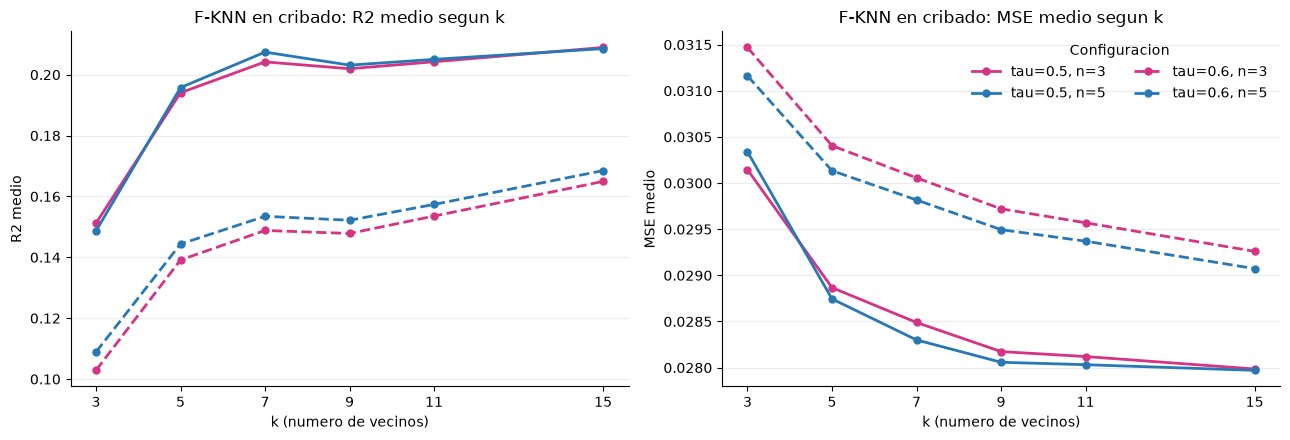

In [20]:
# Grafica del cribado: compara k manteniendo visibles tau y n.
parametros_plot = resultados_cv_fknn_exploracion["metodo"].str.extract(
    r"k=(\d+)\s+tau=([\d.]+)\s+n=(\d+)"
)
graf_fknn = resultados_cv_fknn_exploracion.copy()
graf_fknn["k"] = parametros_plot[0].astype(int)
graf_fknn["tau"] = parametros_plot[1].astype(float)
graf_fknn["n"] = parametros_plot[2].astype(int)
resumen_graf_fknn = (
    graf_fknn.groupby(["k", "tau", "n"], as_index=False)
    .agg(R2_medio=("R2", "mean"), MSE_medio=("MSE", "mean"))
)

colores_n = {3: "#D63384", 5: "#2878B5"}
trazos_tau = {0.5: "-", 0.6: "--"}
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))
for (tau, n), sub in resumen_graf_fknn.groupby(["tau", "n"]):
    sub = sub.sort_values("k")
    etiqueta = f"tau={tau:g}, n={n}"
    estilo = dict(
        marker="o", linewidth=2, markersize=5,
        color=colores_n[n], linestyle=trazos_tau[tau], label=etiqueta,
    )
    ejes[0].plot(sub["k"], sub["R2_medio"], **estilo)
    ejes[1].plot(sub["k"], sub["MSE_medio"], **estilo)

for ax, metrica, titulo in zip(
    ejes, ["R2_medio", "MSE_medio"], ["R2 medio", "MSE medio"]):
    ax.set_xlabel("k (numero de vecinos)")
    ax.set_ylabel(titulo)
    ax.set_title(f"F-KNN en cribado: {titulo} segun k")
    ax.set_xticks(FKNN_KS)
    ax.grid(axis="y", alpha=0.25)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
ejes[1].legend(title="Configuracion", frameon=False, ncol=2)
fig.tight_layout()
plt.show()

In [21]:
filas_disponibles = []

for fold, ids_train, id_valid in FOLDS:
    X_fit = np.vstack([matriz(t) for t in ids_train])
    corr = pd.DataFrame(X_fit, columns=variables).corr(method="spearman")

    for j, objetivo in enumerate(variables):
        permitidos = PREDICTORES_POR_INDICE.get(j, ())
        for tau in FKNN_THRESHOLDS:  # 0.5 y 0.6
            candidatos = [
                (variables[i], corr.iloc[j, i])
                for i in permitidos
                if pd.notna(corr.iloc[j, i])
                and abs(corr.iloc[j, i]) >= tau
            ]
            candidatos.sort(key=lambda x: abs(x[1]), reverse=True)

            filas_disponibles.append({
                "fold": fold,
                "objetivo": objetivo,
                "tau": tau,
                "disponibles": len(candidatos),
                "usaria_n3": min(len(candidatos), 3),
                "usaria_n5": min(len(candidatos), 5),
                "candidatos": ", ".join(
                    f"{nombre} (ρ={rho:.2f})" for nombre, rho in candidatos
                ),
            })

tabla_disponibles = pd.DataFrame(filas_disponibles)
display(
    tabla_disponibles.sort_values(
        ["fold", "tau", "disponibles"],
        ascending=[True, True, False],
    ).reset_index(drop=True)
)

,fold,objetivo,tau,disponibles,usaria_n3,usaria_n5,candidatos
0,cv_temporal_1,Outdoor Temperature(°C),0.5,5,3,5,"Outdoor Humidity(%) (ρ=-0.92), Indoor Temperat..."
1,cv_temporal_1,Outdoor Humidity(%),0.5,5,3,5,"Outdoor Temperature(°C) (ρ=-0.92), Light(lux) ..."
2,cv_temporal_1,Wind Speed(km/h),0.5,4,3,4,"Gust(km/h) (ρ=0.96), Light(lux) (ρ=0.57), Outd..."
3,cv_temporal_1,Gust(km/h),0.5,4,3,4,"Wind Speed(km/h) (ρ=0.96), Light(lux) (ρ=0.58)..."
4,cv_temporal_1,Indoor Temperature(°C),0.5,3,3,3,"Outdoor Temperature(°C) (ρ=0.79), Outdoor Humi..."
5,cv_temporal_1,Indoor Humidity(%),0.5,3,3,3,"Outdoor Humidity(%) (ρ=0.71), Indoor Temperatu..."
6,cv_temporal_1,Light(lux),0.5,3,3,3,"Outdoor Temperature(°C) (ρ=0.77), Outdoor Humi..."
7,cv_temporal_1,WindChill(°C),0.5,2,2,2,"Outdoor Temperature(°C) (ρ=1.00), Wind Speed(k..."
8,cv_temporal_1,Absolute Pressure(hpa),0.5,0,0,0,
9,cv_temporal_1,DewPoint(°C),0.5,0,0,0,


In [22]:
# Despues de revisar la tabla y la grafica, escribe aqui los tres metodos elegidos.
NOMBRES_FKNN_FINALISTAS = ["F-KNN k=15 tau=0.5 n=3","F-KNN k=7 tau=0.5 n=3","F-KNN k=9 tau=0.5 n=3"]

In [23]:
# Etapa 2: confirmar las tres finalistas elegidas manualmente con las diez semillas.
if len(NOMBRES_FKNN_FINALISTAS) != FKNN_N_FINALISTAS:
    raise ValueError(
        f"Ingresa exactamente {FKNN_N_FINALISTAS} finalistas en NOMBRES_FKNN_FINALISTAS "
        "despues de revisar la tabla y la grafica de exploracion."
    )
if len(set(NOMBRES_FKNN_FINALISTAS)) != FKNN_N_FINALISTAS:
    raise ValueError("Las finalistas deben ser tres configuraciones distintas.")
no_disponibles = set(NOMBRES_FKNN_FINALISTAS) - set(tabla_fknn_exploracion.index)
if no_disponibles:
    raise ValueError(f"Finalistas no encontradas en la exploracion: {sorted(no_disponibles)}")
partes_cv_fknn = []
for fold, ids_train, id_valid in FOLDS:
    for nombre in NOMBRES_FKNN_FINALISTAS:
        partes_cv_fknn.append(evaluar_en_tramo(nombre, ids_train, id_valid, fold=fold))
resultados_cv_fknn = pd.concat(partes_cv_fknn, ignore_index=True)
guardar_resultados(resultados_cv_fknn, "fknn_train_cv")

tabla_fknn = (
    resultados_cv_fknn.groupby("metodo")
    .agg(R2_medio=("R2", "mean"), R2_sd=("R2", "std"), MSE_medio=("MSE", "mean"), escenarios=("MSE", "count"))
    .sort_values(["R2_medio", "MSE_medio"], ascending=[False, True])
)
display(tabla_fknn.round(4))
print("Resultados de confirmacion F-KNN en CV temporal de ajuste; elige un finalista para validation.")

/home/codespace/.local/lib/python3.14/site-packages/pandas/core/nanops.py:1673: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


/home/codespace/.local/lib/python3.14/site-packages/pandas/core/nanops.py:1673: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]
/home/codespace/.local/lib/python3.14/site-packages/pandas/core/nanops.py:1673: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


Guardado: ../data/gold/resultados_modelos/fknn_train_cv.csv | filas: 5460


,R2_medio,R2_sd,MSE_medio,escenarios
metodo,,,,
F-KNN k=15 tau=0.5 n=3,0.1961,0.5103,0.0280,1820
F-KNN k=7 tau=0.5 n=3,0.1907,0.4811,0.0286,1820
F-KNN k=9 tau=0.5 n=3,0.1882,0.5135,0.0282,1820


Resultados de confirmacion F-KNN en CV temporal de ajuste; elige un finalista para validation.


In [24]:
# Se elige el FKNN finalista para validation.
NOMBRE_FKNN_FINALISTA_VALIDACION = "F-KNN k=15 tau=0.5 n=3"

if NOMBRE_FKNN_FINALISTA_VALIDACION not in NOMBRES_FKNN_FINALISTAS:
    raise ValueError(
        "Ingresa en NOMBRE_FKNN_FINALISTA_VALIDACION exactamente uno de los tres "
        "nombres incluidos en NOMBRES_FKNN_FINALISTAS, segun la tabla de confirmacion."
    )

resultados_val_fknn = evaluar_en_tramo(
    NOMBRE_FKNN_FINALISTA_VALIDACION, ["ajuste"], "validacion",
)
guardar_resultados(resultados_val_fknn, "fknn_validation_2018")
display(resultados_val_fknn.groupby(["metodo", "patron", "pct_objetivo"])[["R2", "MSE"]].mean().round(4))


Guardado: ../data/gold/resultados_modelos/fknn_validation_2018.csv | filas: 790


R2     MSE
metodo                 patron   pct_objetivo                
F-KNN k=15 tau=0.5 n=3 disjoint 5            -0.0215  0.0124
                                10            0.2430  0.0144
                                20            0.3853  0.0115
                                30            0.4324  0.0132
                                40            0.3710  0.0159
                                50            0.2987  0.0187
                       overlap  5            -2.7673  0.0236
                                10           -0.0961  0.0211
                                20            0.1028  0.0230
                                30            0.1016  0.0228
                                40            0.1687  0.0229
                                50            0.1302  0.0249

### Diagnóstico del R² en validation: Linear, KNN y F-KNN

Estas tablas reutilizan los resultados ya calculados: resumen la variabilidad del R² por escenario y muestran cada escenario disjoint del 5 %. No vuelven a entrenar modelos ni modifican los DataFrames de resultados. Este desglose es por escenario/semilla; el R² por variable no se conserva en los resultados actuales y requeriría instrumentar y volver a ejecutar las evaluaciones.


In [25]:
resultados_diagnostico_r2 = pd.concat(
    [
        resultados_val_linear,
        resultados_val_knn,
        resultados_val_fknn,
    ],
    ignore_index=True,
).copy()

tabla_r2_por_escenario = (
    resultados_diagnostico_r2
    .groupby(["metodo", "patron", "pct_objetivo"], as_index=False)
    .agg(
        escenarios=("R2", "count"),
        R2_medio=("R2", "mean"),
        R2_mediana=("R2", "median"),
        R2_sd=("R2", "std"),
        R2_min=("R2", "min"),
        R2_max=("R2", "max"),
        MSE_medio=("MSE", "mean"),
        pct_real_medio=("pct_real", "mean"),
        n_variables_medio=("n_variables", "mean"),
    )
    .sort_values(["patron", "metodo", "pct_objetivo"])
)
display(tabla_r2_por_escenario.round(4))

detalle_disjoint_5 = (
    resultados_diagnostico_r2.loc[
        (resultados_diagnostico_r2["patron"] == "disjoint")
        & (resultados_diagnostico_r2["pct_objetivo"] == 5),
        ["metodo", "duracion", "semilla", "n_variables", "pct_real", "R2", "MSE"],
    ]
    .sort_values(["metodo", "R2"], ascending=[True, True])
    .reset_index(drop=True)
)
display(detalle_disjoint_5.round(4))


,metodo,patron,pct_objetivo,escenarios,R2_medio,R2_mediana,R2_sd,R2_min,R2_max,MSE_medio,pct_real_medio,n_variables_medio
0,F-KNN k=15 tau=0.5 n=3,disjoint,5,90,-0.0215,0.2936,1.3456,-10.5932,0.9137,0.0124,4.5610,4.7778
1,F-KNN k=15 tau=0.5 n=3,disjoint,10,80,0.2430,0.3735,0.5611,-2.5300,0.8155,0.0144,9.7810,5.4375
2,F-KNN k=15 tau=0.5 n=3,disjoint,20,90,0.3853,0.4690,0.3665,-1.5150,0.7546,0.0115,20.6933,6.1222
3,F-KNN k=15 tau=0.5 n=3,disjoint,30,100,0.4324,0.4423,0.1743,0.0317,0.6813,0.0132,30.5339,6.8700
4,F-KNN k=15 tau=0.5 n=3,disjoint,40,50,0.3710,0.3648,0.1398,0.1534,0.6145,0.0159,39.4474,8.5600
5,F-KNN k=15 tau=0.5 n=3,disjoint,50,50,0.2987,0.3105,0.1145,-0.0487,0.4527,0.0187,51.7616,8.5000
12,KNN k=13,disjoint,5,90,-0.0928,0.2152,1.3970,-9.8099,0.7707,0.0152,4.5610,4.7778
13,KNN k=13,disjoint,10,80,0.2839,0.3131,0.3002,-1.7365,0.7391,0.0169,9.7810,5.4375
14,KNN k=13,disjoint,20,90,0.3165,0.3849,0.2058,-0.6170,0.5494,0.0163,20.6933,6.1222
15,KNN k=13,disjoint,30,100,0.3478,0.3505,0.0855,0.1568,0.5060,0.0173,30.5339,6.8700


,metodo,duracion,semilla,n_variables,pct_real,R2,MSE
0,F-KNN k=15 tau=0.5 n=3,3d,205,1,3.9550,-10.5932,0.0004
1,F-KNN k=15 tau=0.5 n=3,6h,210,11,3.6254,-4.1324,0.0096
2,F-KNN k=15 tau=0.5 n=3,6h,205,11,3.6254,-2.2443,0.0152
3,F-KNN k=15 tau=0.5 n=3,6h,208,11,3.6254,-1.9676,0.0189
4,F-KNN k=15 tau=0.5 n=3,6h,202,11,3.6254,-1.4796,0.0070
...,...,...,...,...,...,...,...
265,LinearRegression,3d,209,1,3.9550,0.6358,0.0139
266,LinearRegression,6h,207,1,5.6029,0.6412,0.0163
267,LinearRegression,1h,202,1,5.4381,0.6601,0.0113
268,LinearRegression,1h,203,2,5.4930,0.6812,0.0102


## 7. Resultados y graficas comparativas

Esta sección reporta los resultados de `validacion` 2018 para comparar los candidatos de cada familia. También presenta el promedio out-of-fold de los dos folds dentro de `ajuste` como referencia. No selecciona un ganador global ni consulta `evaluacion` 2019, que queda reservada para el test de una entrega posterior.


In [26]:
from matplotlib.lines import Line2D
# Combina los resultados ya calculados en validation.
comparacion_val = pd.concat(
    [
        resultados_val_baseline,
        resultados_val_knn,
        resultados_val_linear,
        resultados_val_fknn,
    ],
    ignore_index=True,
)

def nombre_grafica(metodo):
    if metodo == "LinearRegression":
        return "Linear"
    if metodo == "Mediana":
        return "Median"
    if metodo == "Media":
        return "Mean"
    if metodo == "Moda":
        return "Mode"
    if metodo.startswith("KNN"):
        return "KNN"
    if metodo.startswith("F-KNN"):
        return metodo
    return metodo

comparacion_val["modelo"] = comparacion_val["metodo"].map(nombre_grafica)

# Promedio entre semillas para cada patrón y porcentaje.
resumen_val = (
    comparacion_val
    .groupby(["patron", "pct_objetivo", "modelo"], as_index=False)
    .agg(R2=("R2", "mean"), MSE=("MSE", "mean"))
)

display(
    resumen_val.pivot(
        index=["patron", "pct_objetivo"], columns="modelo", values=["R2", "MSE"],
    ).round(4)
)

modelos_fknn = sorted(modelo for modelo in comparacion_val["modelo"].unique() if modelo.startswith("F-KNN"))
orden_modelos = ["Linear", "Median", "Mean", "Mode", "KNN"] + modelos_fknn
colores = {
    "Linear": "#D42A87",
    "Median": "#FF5A65",
    "Mean": "#D4B735",
    "Mode": "#9B7F18",
    "KNN": "#43B9E5",
}
for i, modelo in enumerate(modelos_fknn):
    colores[modelo] = plt.get_cmap("tab10")(i)

def validation_performance_plot(PORCENTAJE_MAX):
    for patron in ["overlap", "disjoint"]:
        datos_patron = resumen_val[
            (resumen_val["patron"] == patron)
            & (resumen_val["pct_objetivo"] <= PORCENTAJE_MAX)
        ]

        fig, ejes = plt.subplots(1, 2, figsize=(12, 4.5))

        for modelo in orden_modelos:
            sub = (
                datos_patron[datos_patron["modelo"] == modelo]
                .sort_values("pct_objetivo")
            )
            if sub.empty:
                continue

            estilo = {
                "color": colores[modelo],
                "linewidth": 2,
                "marker": "o",
                "markersize": 4,
            }
            ejes[0].plot(sub["pct_objetivo"], sub["R2"], **estilo)
            ejes[1].plot(sub["pct_objetivo"], sub["MSE"], **estilo)

        porcentajes = sorted(datos_patron["pct_objetivo"].unique())

        ejes[0].set_title("R²")
        ejes[0].set_ylabel("R² medio")
        ejes[1].set_title("MSE")
        ejes[1].set_ylabel("MSE normalizado medio")

        for ax in ejes:
            ax.set_xlabel("Porcentaje objetivo de faltantes (%)")
            ax.set_xticks(porcentajes)
            ax.grid(axis="y", color="#D9E1E8", linewidth=0.8)
            ax.spines["top"].set_visible(False)
            ax.spines["right"].set_visible(False)

        leyenda = [
            Line2D([0], [0], color=colores[m], marker="o", linewidth=2, label=m)
            for m in orden_modelos
            if m in datos_patron["modelo"].unique()
        ]

        fig.suptitle(
            f"Desempeño en validation 2018 — {patron.capitalize()}",
            y=0.99,
        )

        fig.legend(
            handles=leyenda,
            loc="upper center",
            bbox_to_anchor=(0.5, 0.93),
            ncol=len(leyenda),       # Una fila
            fontsize=9,
            handlelength=1.4,
            columnspacing=1.0,
            handletextpad=0.4,
            frameon=False,
        )

        fig.tight_layout(rect=[0, 0, 1, 0.89])
        plt.show()


R2                                  \
modelo                F-KNN k=15 tau=0.5 n=3     KNN  Linear    Mean  Median   
patron   pct_objetivo                                                          
disjoint 5                           -0.0215 -0.0928 -0.2700 -1.0257 -0.6758   
         10                           0.2430  0.2839  0.2290 -0.1715 -0.1810   
         20                           0.3853  0.3165  0.3124 -0.1019 -0.1262   
         30                           0.4324  0.3478  0.3654 -0.0586 -0.1143   
         40                           0.3710  0.2974  0.2829 -0.0636 -0.1111   
         50                           0.2987  0.2525  0.2364 -0.0495 -0.1050   
overlap  5                           -2.7673 -2.8368 -2.9490 -3.4011 -2.3147   
         10                          -0.0961 -0.0382 -0.1246 -0.2606 -0.1839   
         20                           0.1028  0.1113  0.0172 -0.1466 -0.1477   
         30                           0.1016  0.0942  0.0637 -0.1020 -0.1247   
         40                           0.1687  0.1187  0.0837 -0.0678 -0.1039   
         50                           0.1302  0.1217  0.1147 -0.0693 -0.1091   

                                                 MSE                          \
modelo                   Mode F-KNN k=15 tau=0.5 n=3     KNN  Linear    Mean   
patron   pct_objetivo                                                          
disjoint 5            -0.9455                 0.0124  0.0152  0.0150  0.0290   
         10           -0.5679                 0.0144  0.0169  0.0166  0.0333   
         20           -0.6061                 0.0115  0.0163  0.0148  0.0341   
         30           -0.5911                 0.0132  0.0173  0.0162  0.0340   
         40           -0.5598                 0.0159  0.0195  0.0200  0.0343   
         50           -0.5608                 0.0187  0.0209  0.0216  0.0337   
overlap  5            -2.4240                 0.0236  0.0247  0.0262  0.0325   
         10           -0.5964                 0.0211  0.0221  0.0225  0.0294   
         20           -0.5166                 0.0230  0.0234  0.0245  0.0323   
         30           -0.5164                 0.0228  0.0232  0.0244  0.0302   
         40           -0.5458                 0.0229  0.0251  0.0264  0.0330   
         50           -0.5469                 0.0249  0.0256  0.0259  0.0342   

                                       
modelo                 Median    Mode  
patron   pct_objetivo                  
disjoint 5             0.0312  0.0400  
         10            0.0363  0.0503  
         20            0.0371  0.0574  
         30            0.0367  0.0567  
         40            0.0367  0.0550  
         50            0.0363  0.0553  
overlap  5             0.0352  0.0494  
         10            0.0312  0.0444  
         20            0.0348  0.0486  
         30            0.0327  0.0467  
         40            0.0351  0.0529  
         50            0.0368  0.0555

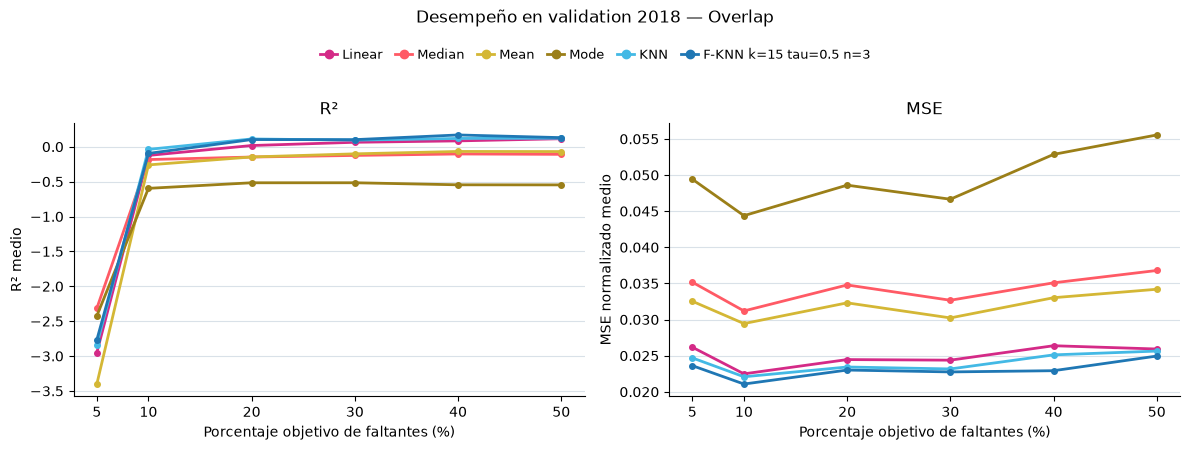

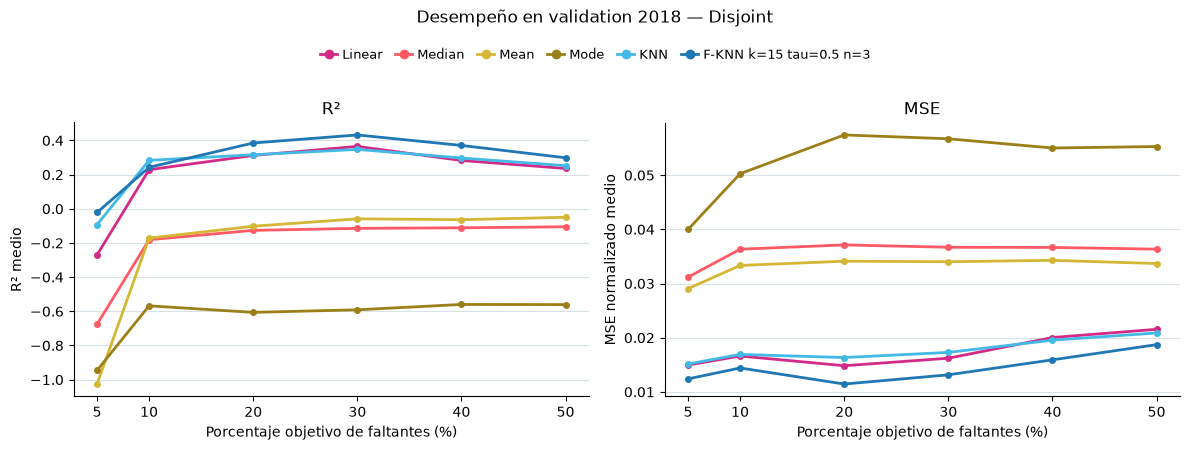

In [27]:
validation_performance_plot(50)

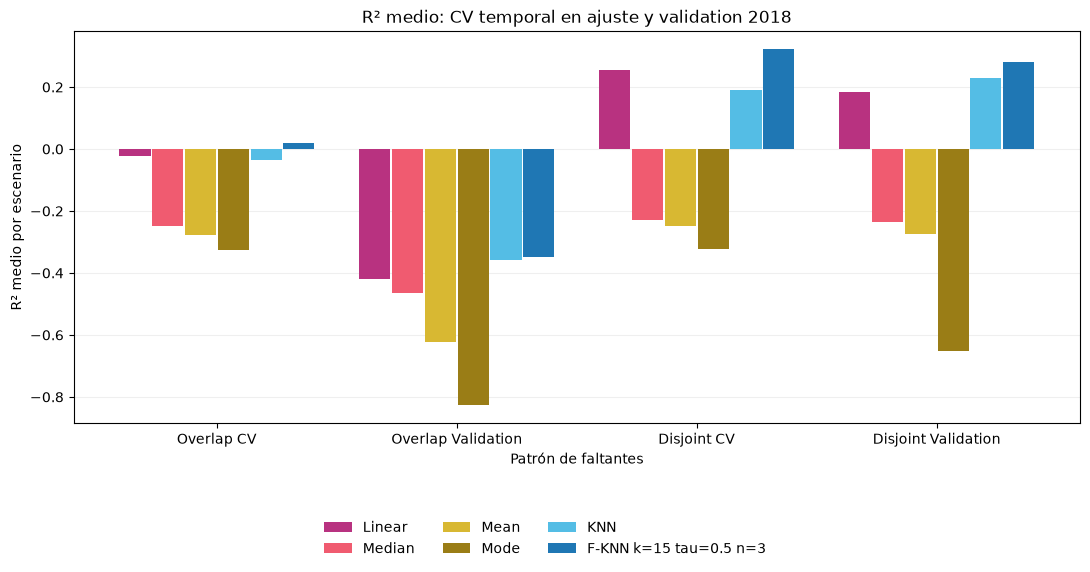

In [28]:
# Resume train CV y validation 2018; no consulta test 2019 ni elige un ganador global.
metodo_knn = resultados_val_knn["metodo"].iloc[0]
metodos_fknn = sorted(resultados_val_fknn["metodo"].unique())

mapas = [
    # Train CV: promedio out-of-fold dentro de ajuste 2018
    (resultados_cv_baseline, "CV", {
        "Median": "Mediana",
        "Mean": "Media",
        "Mode": "Moda",
    }),
    (resultados_cv_linear, "CV", {"Linear": "LinearRegression"}),
    (resultados_cv_knn, "CV", {"KNN": metodo_knn}),
    (resultados_cv_fknn, "CV", {metodo: metodo for metodo in metodos_fknn}),

    # Validation 2018: candidatos para comparación
    (resultados_val_baseline, "Validation", {
        "Median": "Mediana",
        "Mean": "Media",
        "Mode": "Moda",
    }),
    (resultados_val_linear, "Validation", {"Linear": "LinearRegression"}),
    (resultados_val_knn, "Validation", {"KNN": metodo_knn}),
    (resultados_val_fknn, "Validation", {metodo: metodo for metodo in metodos_fknn}),
]

filas = []
for df, fase, equivalencias in mapas:
    for etiqueta, metodo in equivalencias.items():
        sub = df[(df["metodo"] == metodo)& (df["pct_objetivo"] <= 50)]

        for patron, datos_patron in sub.groupby("patron"):
            filas.append({
                "modelo": etiqueta,
                "categoria": f"{patron.capitalize()} {fase}",
                "R2": datos_patron["R2"].mean(),
            })

resumen_barras = pd.DataFrame(filas)

categorias = [
    "Overlap CV",
    "Overlap Validation",
    "Disjoint CV",
    "Disjoint Validation",
]
modelos = ["Linear", "Median", "Mean", "Mode", "KNN"] + metodos_fknn

tabla_barras = (
    resumen_barras
    .pivot(index="categoria", columns="modelo", values="R2")
    .reindex(index=categorias, columns=modelos)
)

colores = {
    "Linear": "#B83280",
    "Median": "#F05B70",
    "Mean": "#D8B832",
    "Mode": "#9A7D16",
    "KNN": "#54BDE5",
}
for i, metodo in enumerate(metodos_fknn):
    colores[metodo] = plt.get_cmap("tab10")(i)

fig, ax = plt.subplots(figsize=(11, 5.8))

x = np.arange(len(categorias))
modelos_presentes = [
    modelo for modelo in modelos
    if modelo in tabla_barras.columns and tabla_barras[modelo].notna().any()
]
ancho = 0.82 / len(modelos_presentes)

for i, modelo in enumerate(modelos_presentes):
    desplazamiento = (i - (len(modelos_presentes) - 1) / 2) * ancho
    ax.bar(
        x + desplazamiento,
        tabla_barras[modelo].to_numpy(),
        width=ancho * 0.95,
        color=colores[modelo],
        label=modelo,
    )

ax.set_xticks(x)
ax.set_xticklabels(categorias)
ax.set_ylabel("R² medio por escenario")
ax.set_xlabel("Patrón de faltantes")
ax.set_title("R² medio: CV temporal en ajuste y validation 2018")
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
handles, labels = ax.get_legend_handles_labels()
fig.legend(
    handles, labels,
    frameon=False,
    ncol=3,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.01),
)

fig.tight_layout(rect=(0, 0.16, 1, 1))
plt.show()

In [29]:
# ===== BLOQUE 2: desempeño por equipo de medición en validación 2018 =====
GRUPO_DE = {v: g for g, cols in CV_GRUPOS.items() for v in cols if v in variables}
MODELOS_DETALLE = ["Media", "KNN k=13", "F-KNN k=15 tau=0.5 n=3"]
PCT_MIN = 20   # con 5-10 % el R2 es muy inestable; cámbialo a 0 si quieres usar todos


def evaluar_detalle(nombre, ids_train, id_eval):
    modelo, X_fit = ajustar_modelo(nombre, ids_train)
    X_real = matriz(id_eval)
    rango = rango_de(X_fit)
    info, mascaras = ESCENARIOS[id_eval]
    filas = []
    for esc in info.itertuples(index=False):
        mascara = mascaras[int(esc.id)]
        X_oculto = X_real.copy()
        X_oculto[mascara] = np.nan
        X_imp = a_unidades_originales(modelo, modelo.transform(X_oculto))
        celdas = mascara & np.isfinite(X_real) & np.isfinite(X_imp)
        for j, v in enumerate(variables):
            sel = celdas[:, j]
            if sel.sum() < 2:
                continue
            err = ((X_imp[sel, j] - X_real[sel, j]) / rango[j]) ** 2
            filas.append({"metodo": nombre, "patron": esc.patron,
                          "pct_objetivo": esc.pct_objetivo, "duracion": esc.duracion,
                          "semilla": esc.semilla, "variable": v, "equipo": GRUPO_DE[v],
                          "n_celdas": int(sel.sum()), "sse_norm": float(err.sum()),
                          "R2": r2_score(X_real[sel, j], X_imp[sel, j])})
    return pd.DataFrame(filas)


det = pd.concat([evaluar_detalle(n, ["ajuste"], "validacion") for n in MODELOS_DETALLE],
                ignore_index=True)
guardar_resultados(det, "detalle_por_variable_validacion_2018")

d = det[det["pct_objetivo"] >= PCT_MIN]
res_eq = d.groupby(["metodo", "equipo"]).agg(
    R2=("R2", "mean"), sse=("sse_norm", "sum"), n=("n_celdas", "sum"))
res_eq["MSE"] = res_eq["sse"] / res_eq["n"]
display(res_eq[["R2", "MSE"]].round(4).unstack("metodo"))

# Filas listas para pegar en la Tabla 7 del informe (.tex)
EQUIPOS_ES = {"interior": "Interior", "termohigrometro": "Termohigrómetro",
              "barometro": "Barómetro", "anemometro": "Anemómetro",
              "pluviometro": "Pluviómetro", "luz": "Luz"}


def f3(x):
    t = f"{abs(x):.3f}".replace(".", ",")
    return ("\\mn " + t) if x < 0 else t


def f4(x):
    return f"{x:.4f}".replace(".", ",")


for eq, nombre_es in EQUIPOS_ES.items():
    r2s = [f3(res_eq.loc[(m, eq), "R2"]) for m in MODELOS_DETALLE]
    mses = [f4(res_eq.loc[(m, eq), "MSE"]) for m in MODELOS_DETALLE]
    print(f"{nombre_es} & " + " & ".join(r2s + mses) + r" \\")

    

Guardado: ../data/gold/resultados_modelos/detalle_por_variable_validacion_2018.csv | filas: 16665


R2                   \
metodo          F-KNN k=15 tau=0.5 n=3 KNN k=13   Media   
equipo                                                    
anemometro                      0.1748   0.1513 -0.0202   
barometro                      -0.0028  -0.1108 -0.3262   
interior                        0.2496   0.3102 -0.0513   
luz                             0.1792   0.2847 -0.0250   
pluviometro                    -0.5321  -0.3796 -0.3129   
termohigrometro                 0.3974   0.2668 -0.0615   

                                   MSE                   
metodo          F-KNN k=15 tau=0.5 n=3 KNN k=13   Media  
equipo                                                   
anemometro                      0.0166   0.0170  0.0210  
barometro                       0.0353   0.0379  0.0463  
interior                        0.0209   0.0187  0.0303  
luz                             0.0304   0.0257  0.0388  
pluviometro                     0.0036   0.0036  0.0034  
termohigrometro                 0.0168   0.0228  0.0402

Interior & \mn 0,051 & 0,310 & 0,250 & 0,0303 & 0,0187 & 0,0209 \\
Termohigrómetro & \mn 0,061 & 0,267 & 0,397 & 0,0402 & 0,0228 & 0,0168 \\
Barómetro & \mn 0,326 & \mn 0,111 & \mn 0,003 & 0,0463 & 0,0379 & 0,0353 \\
Anemómetro & \mn 0,020 & 0,151 & 0,175 & 0,0210 & 0,0170 & 0,0166 \\
Pluviómetro & \mn 0,313 & \mn 0,380 & \mn 0,532 & 0,0034 & 0,0036 & 0,0036 \\
Luz & \mn 0,025 & 0,285 & 0,179 & 0,0388 & 0,0257 & 0,0304 \\


Prueba de evaluación final

In [30]:
import time

# ===== PRUEBA 2019: evaluación final =====
# Los modelos se ajustan con todo 2018 y se evalúan en 2019 con las máscaras de prueba.
# No se cambia ningún hiperparámetro con estos resultados.
MODELOS_FINALES = [
    "Media", "Mediana", "Moda",
    "LinearRegression",
    "KNN k=13",
    "F-KNN k=15 tau=0.5 n=3",
]
IDS_TRAIN_FINAL = ["ajuste", "validacion"]   # todo 2018
ID_PRUEBA = "evaluacion"                     # 2019

# Revisión de orden temporal: el entrenamiento es anterior a la prueba.
assert datos["validacion"].index.max() < datos[ID_PRUEBA].index.min()
print("Entrenamiento:", datos["ajuste"].index.min(), "->", datos["validacion"].index.max())
print("Prueba       :", datos[ID_PRUEBA].index.min(), "->", datos[ID_PRUEBA].index.max())
print("Escenarios de prueba:", len(ESCENARIOS[ID_PRUEBA][0]))

partes = []
for nombre in MODELOS_FINALES:
    t0 = time.time()
    partes.append(evaluar_en_tramo(nombre, IDS_TRAIN_FINAL, ID_PRUEBA))
    print(f"{nombre:28s} listo en {time.time() - t0:5.0f} s")

resultados_test = pd.concat(partes, ignore_index=True)[COLUMNAS_RESULTADOS]
guardar_resultados(resultados_test, "resultados_prueba_2019")

Entrenamiento: 2018-08-21 06:00:00 -> 2018-09-30 12:00:00
Prueba       : 2019-05-01 01:30:00 -> 2019-06-20 08:30:00
Escenarios de prueba: 1170


Media                        listo en     6 s
Mediana                      listo en     6 s
Moda                         listo en     6 s
LinearRegression             listo en     8 s
KNN k=13                     listo en   272 s
F-KNN k=15 tau=0.5 n=3       listo en   378 s
Guardado: ../data/gold/resultados_modelos/resultados_prueba_2019.csv | filas: 7020


In [31]:
test = resultados_test[resultados_test["pct_objetivo"] <= 50].copy()

# 1) R² y MSE por patrón y porcentaje (promedio entre escenarios)
resumen_test = (
    test.groupby(["patron", "pct_objetivo", "metodo"], as_index=False)
        .agg(R2=("R2", "mean"), MSE=("MSE", "mean"))
)
print("R² medio por patrón y porcentaje")
display(resumen_test.pivot(index=["patron", "pct_objetivo"], columns="metodo", values="R2").round(4))
print("MSE medio por patrón y porcentaje")
display(resumen_test.pivot(index=["patron", "pct_objetivo"], columns="metodo", values="MSE").round(4))

# 2) Resumen por patrón, con variabilidad (todos los porcentajes)
tabla_prueba = (
    test.groupby(["patron", "metodo"])
        .agg(escenarios=("R2", "size"), R2_medio=("R2", "mean"), R2_sd=("R2", "std"),
             R2_min=("R2", "min"), MSE_medio=("MSE", "mean"))
        .round(4)
)
print("Resumen por patrón (5 a 50 %)")
display(tabla_prueba)

# 3) Lo mismo sin el 5 %, donde el R² es muy inestable
tabla_prueba_10 = (
    test[test["pct_objetivo"] >= 10]
        .groupby(["patron", "metodo"])
        .agg(escenarios=("R2", "size"), R2_medio=("R2", "mean"), R2_sd=("R2", "std"),
             MSE_medio=("MSE", "mean"))
        .round(4)
)
print("Resumen por patrón (10 a 50 %)")
display(tabla_prueba_10)

R² medio por patrón y porcentaje


metodo                 F-KNN k=15 tau=0.5 n=3  KNN k=13  LinearRegression  \
patron   pct_objetivo                                                       
disjoint 5                             0.1943    0.0450            0.0101   
         10                            0.2281    0.0418            0.0259   
         20                            0.3026    0.1464            0.1591   
         30                            0.2710    0.1367            0.1426   
         40                            0.2048    0.0526            0.0262   
         50                            0.1422    0.0246           -0.0132   
overlap  5                            -0.1762   -0.2583           -0.3118   
         10                           -0.0268   -0.1278           -0.1322   
         20                           -0.0791   -0.1574           -0.1657   
         30                           -0.0192   -0.0953           -0.1138   
         40                           -0.0251   -0.1045           -0.1176   
         50                           -0.0772   -0.1277           -0.1324   

metodo                  Media  Mediana    Moda  
patron   pct_objetivo                           
disjoint 5            -0.4264  -0.4308 -0.5821  
         10           -0.4661  -0.4249 -0.5612  
         20           -0.3480  -0.3309 -0.7307  
         30           -0.2999  -0.2991 -0.7245  
         40           -0.3178  -0.3096 -0.6118  
         50           -0.2972  -0.2879 -0.6489  
overlap  5            -0.6725  -0.5922 -0.6574  
         10           -0.3671  -0.3458 -0.6155  
         20           -0.3646  -0.3452 -0.5906  
         30           -0.2993  -0.2977 -0.5777  
         40           -0.2842  -0.2806 -0.6011  
         50           -0.2942  -0.2929 -0.6725

MSE medio por patrón y porcentaje


metodo                 F-KNN k=15 tau=0.5 n=3  KNN k=13  LinearRegression  \
patron   pct_objetivo                                                       
disjoint 5                             0.0165    0.0202            0.0205   
         10                            0.0183    0.0231            0.0234   
         20                            0.0160    0.0207            0.0197   
         30                            0.0179    0.0221            0.0216   
         40                            0.0210    0.0253            0.0261   
         50                            0.0234    0.0268            0.0282   
overlap  5                             0.0263    0.0286            0.0295   
         10                            0.0259    0.0286            0.0288   
         20                            0.0272    0.0294            0.0296   
         30                            0.0277    0.0299            0.0305   
         40                            0.0288    0.0311            0.0316   
         50                            0.0303    0.0319            0.0320   

metodo                  Media  Mediana    Moda  
patron   pct_objetivo                           
disjoint 5             0.0352   0.0364  0.0449  
         10            0.0393   0.0388  0.0472  
         20            0.0386   0.0383  0.0569  
         30            0.0393   0.0393  0.0586  
         40            0.0390   0.0389  0.0529  
         50            0.0393   0.0391  0.0555  
overlap  5             0.0369   0.0370  0.0463  
         10            0.0363   0.0362  0.0479  
         20            0.0367   0.0366  0.0484  
         30            0.0374   0.0374  0.0498  
         40            0.0379   0.0379  0.0519  
         50            0.0390   0.0389  0.0560

Resumen por patrón (5 a 50 %)


escenarios  R2_medio   R2_sd  R2_min  \
patron   metodo                                                         
disjoint F-KNN k=15 tau=0.5 n=3         680    0.2336  0.3237 -4.2825   
         KNN k=13                       680    0.0816  0.3012 -3.3221   
         LinearRegression               680    0.0686  0.3479 -5.3852   
         Media                          680   -0.3676  0.3408 -3.5409   
         Mediana                        680   -0.3550  0.2812 -2.8310   
         Moda                           680   -0.6463  0.3263 -1.9322   
overlap  F-KNN k=15 tau=0.5 n=3         490   -0.0663  0.3855 -2.2102   
         KNN k=13                       490   -0.1447  0.3176 -2.2102   
         LinearRegression               490   -0.1619  0.3321 -2.2102   
         Media                          490   -0.3801  0.3987 -3.8669   
         Mediana                        490   -0.3589  0.3028 -3.0188   
         Moda                           490   -0.6166  0.2430 -2.0835   

                                 MSE_medio  
patron   metodo                             
disjoint F-KNN k=15 tau=0.5 n=3     0.0183  
         KNN k=13                   0.0225  
         LinearRegression           0.0226  
         Media                      0.0383  
         Mediana                    0.0384  
         Moda                       0.0524  
overlap  F-KNN k=15 tau=0.5 n=3     0.0276  
         KNN k=13                   0.0299  
         LinearRegression           0.0303  
         Media                      0.0373  
         Mediana                    0.0373  
         Moda                       0.0499

Resumen por patrón (10 a 50 %)


escenarios  R2_medio   R2_sd  MSE_medio
patron   metodo                                                         
disjoint F-KNN k=15 tau=0.5 n=3         550    0.2429  0.2398     0.0187
         KNN k=13                       550    0.0902  0.2376     0.0230
         LinearRegression               550    0.0825  0.2399     0.0231
         Media                          550   -0.3537  0.2676     0.0391
         Mediana                        550   -0.3370  0.2202     0.0389
         Moda                           550   -0.6614  0.2942     0.0542
overlap  F-KNN k=15 tau=0.5 n=3         410   -0.0449  0.3419     0.0279
         KNN k=13                       410   -0.1226  0.2786     0.0301
         LinearRegression               410   -0.1327  0.2861     0.0304
         Media                          410   -0.3230  0.2135     0.0374
         Mediana                        410   -0.3133  0.1609     0.0373
         Moda                           410   -0.6086  0.2045     0.0506

In [32]:
FINAL = "F-KNN k=15 tau=0.5 n=3"
mse_medio = test.groupby(["patron", "metodo"])["MSE"].mean().unstack("metodo")
for patron in mse_medio.index:
    f = mse_medio.loc[patron, FINAL]
    print(
        f"{patron:9s} | F-KNN vs Media: {1 - f / mse_medio.loc[patron, 'Media']:6.1%}"
        f" | vs KNN: {1 - f / mse_medio.loc[patron, 'KNN k=13']:6.1%}"
        f" | vs Lineal: {1 - f / mse_medio.loc[patron, 'LinearRegression']:6.1%}"
    )

disjoint  | F-KNN vs Media:  52.4% | vs KNN:  18.9% | vs Lineal:  19.1%
overlap   | F-KNN vs Media:  25.9% | vs KNN:   7.5% | vs Lineal:   8.7%


## 7. Optimización de hiperparámetros

**Por qué esta sección.** En la Fase 2 ya se hizo una búsqueda en rejilla de `k` (KNN) y de 24 configuraciones de F-KNN, pero los mejores valores quedaron en el borde de lo explorado (k=19 en KNN; τ=0,5 y n=3, los más bajos, en F-KNN) y la regresión lineal no se afinó. Aquí se abre el espacio de búsqueda y se agrega la regresión lineal.

**Cómo se busca.** `GridSearchCV` de scikit-learn no se puede usar tal cual: la métrica se calcula sobre celdas ocultas con máscaras propias y folds temporales. Se usan `ParameterGrid` (rejilla) y `ParameterSampler` (búsqueda aleatoria) con la misma validación cruzada temporal de 2 folds dentro de `ajuste` 2018.

**Sin fuga de datos.** Toda la búsqueda usa solo la CV de `ajuste`; ni `validacion` ni la prueba 2019 intervienen en ninguna elección. Criterio de selección: ranking balanceado entre R² (más alto) y MSE normalizado (más bajo), el mismo de la selección de `k` en la Fase 2.

In [33]:
# ===== 7. OPTIMIZACIÓN DE HIPERPARÁMETROS: infraestructura =====
import time
from sklearn.model_selection import ParameterGrid, ParameterSampler

SEMILLA_BUSQUEDA = 2026                      # reproduce el muestreo aleatorio
SEMILLAS_CRIBADO = [201, 202]                # búsqueda rápida (como en la Fase 2)
SEMILLAS_CONFIRMACION = list(CV_SEMILLAS)    # 201-210: confirmación de finalistas
N_ITER_FKNN = 40                             # configuraciones aleatorias de F-KNN
N_FINALISTAS_FKNN = 5                        # cuántas pasan a la confirmación

# Se amplía crear_modelo para aceptar hiperparámetros dentro del nombre del modelo:
#   "F-KNN k=15 tau=0.5 n=3 ml=2 lg=2-48-96-336"   y   "LinearRegression a=1 v=10 it=5"
# Los nombres antiguos ("F-KNN k=15 tau=0.5 n=3", "LinearRegression") siguen funcionando.
if "_crear_modelo_base" not in globals():
    _crear_modelo_base = crear_modelo


def _parametros(nombre):
    return dict(par.split("=") for par in nombre.split()[1:])


def crear_modelo(nombre):
    if nombre.startswith("F-KNN "):
        p = _parametros(nombre)
        lags = tuple(int(x) for x in p["lg"].split("-")) if "lg" in p else tuple(FKNN_LAGS)
        fknn = FocalizedKNNImputer(
            n_neighbors=int(p["k"]), correlation_threshold=float(p["tau"]),
            n_features=int(p["n"]), lags=lags,
            max_lags=int(p.get("ml", FKNN_MAX_LAGS)),
            predictor_indices=PREDICTORES_POR_INDICE,
        )
        return Pipeline([("fknn", fknn)])
    if nombre.startswith("LinearRegression"):
        p = _parametros(nombre)
        imputador = RegresionLinealIterativa(
            predictor_indices=PREDICTORES_POR_INDICE,
            max_iter=int(p.get("it", 5)), vif_max=float(p.get("v", 10)), alpha=float(p.get("a", 1)),
        )
        return Pipeline([("escalar", MinMaxScaler()), ("imputar", imputador)])
    return _crear_modelo_base(nombre)


def nombre_fknn(k, tau, n, ml, lags):
    return f"F-KNN k={k} tau={tau} n={n} ml={ml} lg={'-'.join(str(x) for x in lags)}"


def nombre_lineal(a, v, it):
    return f"LinearRegression a={a} v={v} it={it}"


def evaluar_busqueda(nombres, semillas, etiqueta):
    """Evalúa cada configuración en los folds temporales de ajuste (nunca toca validación ni prueba)."""
    partes = []
    for i, nombre in enumerate(nombres, start=1):
        t0 = time.time()
        for fold, ids_train, id_valid in FOLDS:
            partes.append(evaluar_en_tramo(nombre, ids_train, id_valid, fold=fold, semillas=semillas))
        print(f"[{etiqueta}] {i:>3}/{len(nombres)} | {nombre} | {time.time() - t0:5.0f} s")
    return pd.concat(partes, ignore_index=True)


def ranking_busqueda(resultados):
    """Ranking balanceado R² (alto) y MSE normalizado (bajo), igual que la selección de k de la Fase 2."""
    t = resultados.groupby("metodo").agg(
        R2_medio=("R2", "mean"), R2_sd=("R2", "std"),
        MSE_medio=("MSE", "mean"), escenarios=("MSE", "count"))
    t["rango_balanceado"] = (t["R2_medio"].rank(ascending=False) + t["MSE_medio"].rank()) / 2
    return t.sort_values(["rango_balanceado", "MSE_medio"]).round(4)


def comparacion_pareada(resultados, base, alternativa):
    """Mismas máscaras para ambos modelos: diferencia escenario por escenario (positivo = alternativa mejor)."""
    a = resultados[resultados["metodo"] == base].reset_index(drop=True)
    b = resultados[resultados["metodo"] == alternativa].reset_index(drop=True)
    assert len(a) == len(b) and np.allclose(a["pct_real"], b["pct_real"]), "Las máscaras no coinciden"
    d_mse, d_r2 = (a["MSE"] - b["MSE"]).to_numpy(), (b["R2"] - a["R2"]).to_numpy()
    return {"base": base, "alternativa": alternativa,
            "mejora_MSE_media": d_mse.mean(), "mejora_MSE_ee": d_mse.std(ddof=1) / np.sqrt(len(d_mse)),
            "mejora_R2_media": np.nanmean(d_r2),
            "pct_escenarios_mejor_MSE": 100 * (d_mse > 0).mean()}

### 7.2 KNN: rejilla ampliada de `k`
En la Fase 2 el mejor `k` (19) estaba en el borde de la rejilla; se amplía hasta 151. Los pesos uniformes ya se compararon con los pesos por distancia en la sección anterior (el artículo también encuentra mejor la versión uniforme).

In [34]:
# ----- 7.2 KNN: búsqueda en rejilla de k (rejilla ampliada: en la Fase 2 el mejor k estaba en el borde, k=19) -----
KS_AMPLIADOS = [9, 13, 19, 25, 31, 41, 51, 75, 101, 151]
partes = [evaluar_knn_varios_k(ids_train, id_valid, KS_AMPLIADOS, fold=fold)
          for fold, ids_train, id_valid in FOLDS]
cv_knn_ampliado = pd.concat(partes, ignore_index=True)
guardar_resultados(cv_knn_ampliado, "busqueda_knn_cv")

rank_knn = ranking_busqueda(cv_knn_ampliado)
display(rank_knn)
NOMBRE_KNN_FINAL = rank_knn.index[0]
if NOMBRE_KNN_FINAL in (f"KNN k={KS_AMPLIADOS[0]}", f"KNN k={KS_AMPLIADOS[-1]}"):
    print("AVISO: el mejor k está en el borde de la rejilla; conviene ampliarla.")
print("KNN elegido por CV temporal:", NOMBRE_KNN_FINAL)

KNN validacion_cv_1: escenario 10/910
KNN validacion_cv_1: escenario 20/910
KNN validacion_cv_1: escenario 30/910
KNN validacion_cv_1: escenario 40/910
KNN validacion_cv_1: escenario 50/910
KNN validacion_cv_1: escenario 60/910
KNN validacion_cv_1: escenario 70/910
KNN validacion_cv_1: escenario 80/910
KNN validacion_cv_1: escenario 90/910
KNN validacion_cv_1: escenario 100/910
KNN validacion_cv_1: escenario 110/910
KNN validacion_cv_1: escenario 120/910
KNN validacion_cv_1: escenario 130/910
KNN validacion_cv_1: escenario 140/910
KNN validacion_cv_1: escenario 150/910
KNN validacion_cv_1: escenario 160/910
KNN validacion_cv_1: escenario 170/910
KNN validacion_cv_1: escenario 180/910
KNN validacion_cv_1: escenario 190/910
KNN validacion_cv_1: escenario 200/910
KNN validacion_cv_1: escenario 210/910
KNN validacion_cv_1: escenario 220/910
KNN validacion_cv_1: escenario 230/910
KNN validacion_cv_1: escenario 240/910
KNN validacion_cv_1: escenario 250/910
KNN validacion_cv_1: escenario 260

,R2_medio,R2_sd,MSE_medio,escenarios,rango_balanceado
metodo,,,,,
KNN k=41,0.1158,0.4620,0.0322,1820,1.5
KNN k=51,0.1168,0.4612,0.0322,1820,1.5
KNN k=31,0.1129,0.4646,0.0322,1820,3.5
KNN k=75,0.1130,0.4622,0.0324,1820,4.0
KNN k=25,0.1103,0.4655,0.0323,1820,4.5
KNN k=19,0.1043,0.4720,0.0324,1820,6.5
KNN k=101,0.1050,0.4629,0.0328,1820,7.0
KNN k=13,0.0954,0.4841,0.0327,1820,7.5
KNN k=9,0.0826,0.5015,0.0329,1820,9.5


KNN elegido por CV temporal: KNN k=41


### 7.3 Regresión lineal (Ridge): rejilla de `alpha`, umbral VIF y rondas
Se prueban 45 combinaciones (5 valores de `alpha` × 3 umbrales de VIF × 3 números de rondas). Si el mejor valor queda en el borde de la rejilla, el cuaderno lo avisa.

In [35]:
# ----- 7.3 Regresión lineal (Ridge): búsqueda en rejilla de alpha, umbral VIF y rondas -----
REJILLA_LINEAL = {"a": [0.01, 0.1, 1, 10, 100], "v": [5, 10, 20], "it": [3, 5, 10]}
nombres_lineal = [nombre_lineal(**p) for p in ParameterGrid(REJILLA_LINEAL)]
print("Configuraciones de la regresión lineal:", len(nombres_lineal))

cv_lineal = evaluar_busqueda(nombres_lineal, semillas=None, etiqueta="Lineal")
guardar_resultados(cv_lineal, "busqueda_lineal_cv")

rank_lineal = ranking_busqueda(cv_lineal)
display(rank_lineal.head(10))
NOMBRE_LINEAL_FINAL = rank_lineal.index[0]
print("Regresión lineal elegida por CV temporal:", NOMBRE_LINEAL_FINAL)
mejor = _parametros(NOMBRE_LINEAL_FINAL)
for clave, valores in REJILLA_LINEAL.items():
    if float(mejor[clave]) in (min(valores), max(valores)):
        print(f"AVISO: {clave}={mejor[clave]} está en el borde de la rejilla; conviene ampliarla.")

Configuraciones de la regresión lineal: 45
[Lineal]   1/45 | LinearRegression a=0.01 v=5 it=3 |     9 s
[Lineal]   2/45 | LinearRegression a=0.01 v=10 it=3 |     9 s
[Lineal]   3/45 | LinearRegression a=0.01 v=20 it=3 |     9 s
[Lineal]   4/45 | LinearRegression a=0.01 v=5 it=5 |    10 s
[Lineal]   5/45 | LinearRegression a=0.01 v=10 it=5 |     9 s
[Lineal]   6/45 | LinearRegression a=0.01 v=20 it=5 |    10 s
[Lineal]   7/45 | LinearRegression a=0.01 v=5 it=10 |    12 s
[Lineal]   8/45 | LinearRegression a=0.01 v=10 it=10 |    12 s
[Lineal]   9/45 | LinearRegression a=0.01 v=20 it=10 |    12 s
[Lineal]  10/45 | LinearRegression a=0.1 v=5 it=3 |    10 s
[Lineal]  11/45 | LinearRegression a=0.1 v=10 it=3 |    10 s
[Lineal]  12/45 | LinearRegression a=0.1 v=20 it=3 |    10 s
[Lineal]  13/45 | LinearRegression a=0.1 v=5 it=5 |    10 s
[Lineal]  14/45 | LinearRegression a=0.1 v=10 it=5 |    11 s
[Lineal]  15/45 | LinearRegression a=0.1 v=20 it=5 |    10 s
[Lineal]  16/45 | LinearRegression 

,R2_medio,R2_sd,MSE_medio,escenarios,rango_balanceado
metodo,,,,,
LinearRegression a=1 v=20 it=10,0.2002,0.4822,0.0301,1820,1.0
LinearRegression a=1 v=20 it=5,0.1864,0.4814,0.0307,1820,2.5
LinearRegression a=0.1 v=20 it=10,0.1909,0.4870,0.0309,1820,4.5
LinearRegression a=1 v=5 it=10,0.1505,0.4677,0.0307,1820,5.0
LinearRegression a=1 v=10 it=10,0.1518,0.4682,0.0308,1820,5.0
LinearRegression a=0.1 v=5 it=10,0.1475,0.4665,0.0308,1820,6.5
LinearRegression a=0.01 v=5 it=10,0.1466,0.4663,0.0309,1820,7.5
LinearRegression a=0.01 v=20 it=10,0.1827,0.4865,0.0313,1820,7.5
LinearRegression a=1 v=5 it=5,0.1451,0.4660,0.0309,1820,9.0


Regresión lineal elegida por CV temporal: LinearRegression a=1 v=20 it=10
AVISO: v=20 está en el borde de la rejilla; conviene ampliarla.
AVISO: it=10 está en el borde de la rejilla; conviene ampliarla.


### 7.4 F-KNN: búsqueda aleatoria en dos etapas
Espacio de 6.720 combinaciones: `k`, umbral de Spearman `tau` (incluye los del artículo: 0,5, 0,75 y 0,9), máximo de variables `n`, máximo de rezagos `ml` y conjunto de rezagos candidatos. Etapa 1: 40 configuraciones aleatorias más la de la Fase 2 como referencia, con 2 semillas. Etapa 2: las 5 mejores y la referencia se confirman con las 10 semillas (201–210).

In [36]:
# ----- 7.4 F-KNN: búsqueda aleatoria en dos etapas -----
# En la Fase 2 el mejor F-KNN quedó en el borde de la rejilla (tau=0.5 era el menor umbral probado y n=3 el menor n);
# por eso el espacio ahora se abre hacia ambos lados. Incluye los umbrales del artículo (0.5, 0.75, 0.9).
ESPACIO_FKNN = {
    "k": [5, 7, 9, 11, 13, 15, 19, 25],
    "tau": [0.2, 0.3, 0.4, 0.5, 0.6, 0.75, 0.9],
    "n": [1, 2, 3, 4, 5, 8],
    "ml": [0, 1, 2, 3],                                  # máximo de rezagos usados
    "lags": [(2, 48, 96, 336), (48, 96, 336), (2, 48, 336), (48, 336), (2, 48, 96)],
}
NOMBRE_FKNN_FASE2 = "F-KNN k=15 tau=0.5 n=3"            # configuración de la Fase 2 (referencia)

muestras = list(ParameterSampler(ESPACIO_FKNN, n_iter=N_ITER_FKNN, random_state=SEMILLA_BUSQUEDA))
nombres_fknn = [nombre_fknn(p["k"], p["tau"], p["n"], p["ml"], p["lags"]) for p in muestras]
nombres_fknn = list(dict.fromkeys([NOMBRE_FKNN_FASE2] + nombres_fknn))   # la referencia siempre se evalúa
print("Espacio total:", len(ParameterGrid(ESPACIO_FKNN)), "| configuraciones evaluadas:", len(nombres_fknn))

# Etapa 1: cribado con 2 semillas
cv_fknn_cribado = evaluar_busqueda(nombres_fknn, SEMILLAS_CRIBADO, "F-KNN cribado")
guardar_resultados(cv_fknn_cribado, "busqueda_fknn_cribado_cv")
rank_cribado = ranking_busqueda(cv_fknn_cribado)
display(rank_cribado.head(15))

# Etapa 2: confirmación con 10 semillas (finalistas + referencia de la Fase 2)
finalistas = list(dict.fromkeys(rank_cribado.index[:N_FINALISTAS_FKNN].tolist() + [NOMBRE_FKNN_FASE2]))
cv_fknn_confirmacion = evaluar_busqueda(finalistas, SEMILLAS_CONFIRMACION, "F-KNN confirmación")
guardar_resultados(cv_fknn_confirmacion, "busqueda_fknn_confirmacion_cv")
rank_confirmacion = ranking_busqueda(cv_fknn_confirmacion)
display(rank_confirmacion)

NOMBRE_FKNN_FINAL = rank_confirmacion.index[0]
print("F-KNN elegido por CV temporal:", NOMBRE_FKNN_FINAL)
mejor = _parametros(NOMBRE_FKNN_FINAL)
for clave, valores in ESPACIO_FKNN.items():
    if clave == "lags":
        continue
    if float(mejor.get(clave, FKNN_MAX_LAGS if clave == "ml" else valores[0])) in (min(valores), max(valores)):
        print(f"AVISO: {clave}={mejor.get(clave)} está en el borde del espacio de búsqueda.")

Espacio total: 6720 | configuraciones evaluadas: 41


/home/codespace/.local/lib/python3.14/site-packages/pandas/core/nanops.py:1673: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


[F-KNN cribado]   1/41 | F-KNN k=15 tau=0.5 n=3 |    19 s


/home/codespace/.local/lib/python3.14/site-packages/pandas/core/nanops.py:1673: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


[F-KNN cribado]   2/41 | F-KNN k=9 tau=0.4 n=8 ml=2 lg=48-336 |    19 s
[F-KNN cribado]   3/41 | F-KNN k=5 tau=0.5 n=8 ml=2 lg=2-48-96 |    20 s


/home/codespace/.local/lib/python3.14/site-packages/pandas/core/nanops.py:1673: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


... (75 outputs left out)

/home/codespace/.local/lib/python3.14/site-packages/pandas/core/nanops.py:1673: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


[F-KNN confirmación]   5/5 | F-KNN k=25 tau=0.3 n=8 ml=1 lg=2-48-96-336 |    95 s
Guardado: ../data/gold/resultados_modelos/busqueda_fknn_confirmacion_cv.csv | filas: 9100


,R2_medio,R2_sd,MSE_medio,escenarios,rango_balanceado
metodo,,,,,
F-KNN k=25 tau=0.4 n=5 ml=1 lg=2-48-96,0.2262,0.4831,0.0277,1820,1.5
F-KNN k=19 tau=0.5 n=5 ml=3 lg=2-48-336,0.1985,0.5264,0.0276,1820,2.5
F-KNN k=19 tau=0.2 n=4 ml=2 lg=2-48-96-336,0.2060,0.5027,0.0283,1820,3.5
F-KNN k=25 tau=0.3 n=8 ml=1 lg=2-48-96-336,0.2088,0.4866,0.0285,1820,3.5
F-KNN k=15 tau=0.5 n=3,0.1961,0.5103,0.0280,1820,4.0


F-KNN elegido por CV temporal: F-KNN k=25 tau=0.4 n=5 ml=1 lg=2-48-96
AVISO: k=25 está en el borde del espacio de búsqueda.


### 7.5 ¿La mejora es real o ruido?
Comparación pareada (mismas máscaras) entre la mejor configuración y la de la Fase 2. Si la diferencia es mínima o solo mejora en la mitad de los escenarios, la decisión honesta es conservar la configuración de la Fase 2.

In [37]:
# ----- 7.5 ¿La mejora es real o ruido? Comparación pareada contra la configuración de la Fase 2 -----
if NOMBRE_FKNN_FINAL != NOMBRE_FKNN_FASE2:
    comp = comparacion_pareada(cv_fknn_confirmacion, NOMBRE_FKNN_FASE2, NOMBRE_FKNN_FINAL)
    for clave, valor in comp.items():
        print(f"{clave:28s}", round(valor, 4) if isinstance(valor, (float, np.floating)) else valor)
    print("(el error estándar es optimista: los escenarios comparten datos)")
else:
    print("La búsqueda confirmó la configuración de la Fase 2; no hay cambios.")

resumen_busqueda = pd.DataFrame([
    {"modelo": "KNN", "configuración final": NOMBRE_KNN_FINAL},
    {"modelo": "Regresión lineal", "configuración final": NOMBRE_LINEAL_FINAL},
    {"modelo": "F-KNN", "configuración final": NOMBRE_FKNN_FINAL},
])
display(resumen_busqueda)
resumen_busqueda.to_csv(RESULTADOS_DIR / "configuraciones_finales.csv", index=False)

base                         F-KNN k=15 tau=0.5 n=3
alternativa                  F-KNN k=25 tau=0.4 n=5 ml=1 lg=2-48-96
mejora_MSE_media             0.0003
mejora_MSE_ee                0.0001
mejora_R2_media              0.0301
pct_escenarios_mejor_MSE     55.0
(el error estándar es optimista: los escenarios comparten datos)


,modelo,configuración final
0,KNN,KNN k=41
1,Regresión lineal,LinearRegression a=1 v=20 it=10
2,F-KNN,F-KNN k=25 tau=0.4 n=5 ml=1 lg=2-48-96


## 8. Reentrenamiento con los mejores hiperparámetros
Se reentrenan la línea base y los tres modelos con las configuraciones elegidas en la sección 7. **8.1** Validación 2018: se ajusta con `ajuste` y se evalúa en `validacion`.

In [38]:
# ===== 8. REENTRENAMIENTO CON LOS MEJORES HIPERPARÁMETROS =====
LINEA_BASE = ["Media", "Mediana", "Moda"]
MODELOS_FINALES_OPT = {
    "Regresión lineal": NOMBRE_LINEAL_FINAL,
    "KNN": NOMBRE_KNN_FINAL,
    "F-KNN": NOMBRE_FKNN_FINAL,
}
ETIQUETAS = {n: n for n in LINEA_BASE}
ETIQUETAS.update({nombre: etiqueta for etiqueta, nombre in MODELOS_FINALES_OPT.items()})
ORDEN_MODELOS = LINEA_BASE + list(MODELOS_FINALES_OPT)
IDS_TRAIN_FINAL = ["ajuste", "validacion"]    # todo 2018
SEMILLAS_PRUEBA = None                        # None = las 1.170 máscaras de la prueba

# 8.1 Validación 2018: se ajusta con `ajuste` y se evalúa en `validacion`
res_val_opt = pd.concat(
    [evaluar_en_tramo(n, ["ajuste"], "validacion") for n in LINEA_BASE + list(MODELOS_FINALES_OPT.values())],
    ignore_index=True)
res_val_opt["modelo"] = res_val_opt["metodo"].map(ETIQUETAS)
guardar_resultados(res_val_opt, "validacion_2018_optimizado")

Guardado: ../data/gold/resultados_modelos/validacion_2018_optimizado.csv | filas: 4740


**8.2 Prueba 2019.** Se ajusta con todo 2018 y se evalúa en 2019. La prueba ya se evaluó una vez con la configuración de la Fase 2; la búsqueda de la sección 7 no la usó, y el informe reporta ambas evaluaciones.

In [39]:
# 8.2 Prueba 2019: se ajusta con todo 2018 y se evalúa en 2019.
# Aviso metodológico: la prueba ya se evaluó una vez con la configuración de la Fase 2 (sección 7 del cuaderno).
# La búsqueda de esta sección usó SOLO la CV temporal de ajuste; la prueba no influyó en ninguna elección.
# Se reportan las dos evaluaciones.
res_test_opt = pd.concat(
    [evaluar_en_tramo(n, IDS_TRAIN_FINAL, "evaluacion", semillas=SEMILLAS_PRUEBA)
     for n in LINEA_BASE + list(MODELOS_FINALES_OPT.values())],
    ignore_index=True)
res_test_opt["modelo"] = res_test_opt["metodo"].map(ETIQUETAS)
guardar_resultados(res_test_opt, "prueba_2019_optimizado")

Guardado: ../data/gold/resultados_modelos/prueba_2019_optimizado.csv | filas: 7020


**8.3 Fase 2 frente a configuración optimizada** en la prueba 2019, por modelo y patrón.

In [40]:
# 8.3 Fase 2 vs configuración optimizada en la prueba 2019
if "resultados_test" not in globals():
    resultados_test = pd.read_csv(RESULTADOS_DIR / "resultados_prueba_2019.csv")
FASE2 = {"Regresión lineal": "LinearRegression", "KNN": "KNN k=13", "F-KNN": "F-KNN k=15 tau=0.5 n=3"}
filas = []
for etiqueta, nombre_f2 in FASE2.items():
    for patron in ["disjoint", "overlap"]:
        a = resultados_test[(resultados_test["metodo"] == nombre_f2) & (resultados_test["patron"] == patron) & (resultados_test["pct_objetivo"] <= 50)]
        b = res_test_opt[(res_test_opt["modelo"] == etiqueta) & (res_test_opt["patron"] == patron) & (res_test_opt["pct_objetivo"] <= 50)]
        filas.append({"modelo": etiqueta, "patron": patron,
                      "config_fase2": nombre_f2, "config_optimizada": MODELOS_FINALES_OPT[etiqueta],
                      "R2_fase2": a["R2"].mean(), "R2_opt": b["R2"].mean(),
                      "MSE_fase2": a["MSE"].mean(), "MSE_opt": b["MSE"].mean()})
comparacion_fases = pd.DataFrame(filas).round(4)
display(comparacion_fases)
comparacion_fases.to_csv(RESULTADOS_DIR / "comparacion_fase2_vs_optimizada_prueba.csv", index=False)

,modelo,patron,config_fase2,config_optimizada,R2_fase2,R2_opt,MSE_fase2,MSE_opt
0,Regresión lineal,disjoint,LinearRegression,LinearRegression a=1 v=20 it=10,0.0686,0.2759,0.0226,0.0187
1,Regresión lineal,overlap,LinearRegression,LinearRegression a=1 v=20 it=10,-0.1619,-0.0528,0.0303,0.0280
2,KNN,disjoint,KNN k=13,KNN k=41,0.0816,0.1245,0.0225,0.0215
3,KNN,overlap,KNN k=13,KNN k=41,-0.1447,-0.1210,0.0299,0.0292
4,F-KNN,disjoint,F-KNN k=15 tau=0.5 n=3,F-KNN k=25 tau=0.4 n=5 ml=1 lg=2-48-96,0.2336,0.2212,0.0183,0.0180
5,F-KNN,overlap,F-KNN k=15 tau=0.5 n=3,F-KNN k=25 tau=0.4 n=5 ml=1 lg=2-48-96,-0.0663,-0.0662,0.0276,0.0273


## 9. Resultados finales organizados
Tablas por patrón y por porcentaje de faltantes (con y sin el 5 %, donde el R² es inestable) y figuras de desempeño; todo se guarda en `data/gold/resultados_modelos` y `figs`.


=== Desempeño en validación 2018 (configuración optimizada): todos los porcentajes ===


escenarios  R2_medio   R2_sd   R2_min  MSE_medio
patron   modelo                                                            
disjoint Media                    460   -0.2755  1.3050 -14.3824     0.0329
         Mediana                  460   -0.2367  0.7618  -8.7951     0.0356
         Moda                     460   -0.6526  0.7744  -8.8167     0.0521
         Regresión lineal         460    0.2948  1.1239 -21.1685     0.0146
         KNN                      460    0.2773  0.4639  -5.1153     0.0166
         F-KNN                    460    0.2785  0.7709 -11.3088     0.0129
overlap  Media                    330   -0.6239  4.3485 -59.3939     0.0319
         Mediana                  330   -0.4642  2.5894 -34.0007     0.0342
         Moda                     330   -0.8267  2.1013 -29.8946     0.0494
         Regresión lineal         330   -0.3509  4.3276 -59.3939     0.0234
         KNN                      330   -0.3345  4.3001 -59.3939     0.0235
         F-KNN                    330   -0.3174  4.3162 -59.3939     0.0218

=== Desempeño en validación 2018 (configuración optimizada): 10 % a 50 % (sin el 5 %, donde el R² es inestable) ===


escenarios  R2_medio   R2_sd  R2_min  MSE_medio
patron   modelo                                                           
disjoint Media                    370   -0.0930  0.1649 -2.3418     0.0339
         Mediana                  370   -0.1299  0.0895 -0.7925     0.0367
         Moda                     370   -0.5814  0.2002 -1.6236     0.0551
         Regresión lineal         370    0.4050  0.3427 -4.0300     0.0148
         KNN                      370    0.3382  0.1443 -0.5169     0.0171
         F-KNN                    370    0.3537  0.4817 -5.0294     0.0130
overlap  Media                    280   -0.1279  0.2489 -2.5896     0.0317
         Mediana                  280   -0.1337  0.1012 -0.9649     0.0340
         Moda                     280   -0.5414  0.2102 -2.0955     0.0494
         Regresión lineal         280    0.0955  0.5386 -5.2642     0.0231
         KNN                      280    0.1042  0.2951 -1.6900     0.0234
         F-KNN                    280    0.1083  0.5094 -5.9855     0.0217

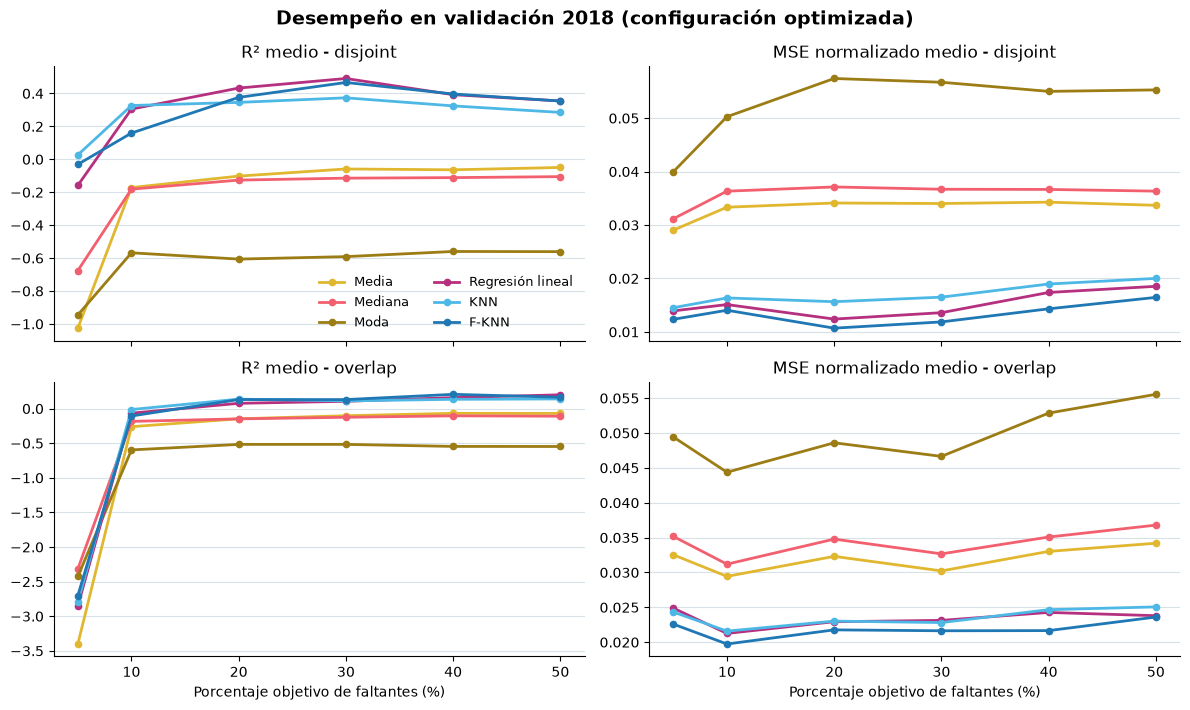


=== Desempeño en la prueba 2019 (configuración optimizada): todos los porcentajes ===


escenarios  R2_medio   R2_sd  R2_min  MSE_medio
patron   modelo                                                           
disjoint Media                    680   -0.3676  0.3408 -3.5409     0.0383
         Mediana                  680   -0.3550  0.2812 -2.8310     0.0384
         Moda                     680   -0.6463  0.3263 -1.9322     0.0524
         Regresión lineal         680    0.2759  0.3915 -5.2111     0.0187
         KNN                      680    0.1245  0.2396 -1.5687     0.0215
         F-KNN                    680    0.2212  0.3921 -6.0074     0.0180
overlap  Media                    490   -0.3801  0.3987 -3.8669     0.0373
         Mediana                  490   -0.3589  0.3028 -3.0188     0.0373
         Moda                     490   -0.6166  0.2430 -2.0835     0.0499
         Regresión lineal         490   -0.0528  0.3894 -2.2102     0.0280
         KNN                      490   -0.1210  0.3308 -2.2102     0.0292
         F-KNN                    490   -0.0662  0.3887 -2.2102     0.0273

=== Desempeño en la prueba 2019 (configuración optimizada): 10 % a 50 % (sin el 5 %, donde el R² es inestable) ===


escenarios  R2_medio   R2_sd  R2_min  MSE_medio
patron   modelo                                                           
disjoint Media                    550   -0.3537  0.2676 -2.5706     0.0391
         Mediana                  550   -0.3370  0.2202 -2.0266     0.0389
         Moda                     550   -0.6614  0.2942 -1.4237     0.0542
         Regresión lineal         550    0.2996  0.3121 -1.7175     0.0188
         KNN                      550    0.1276  0.1923 -1.5687     0.0221
         F-KNN                    550    0.2407  0.2667 -1.5358     0.0182
overlap  Media                    410   -0.3230  0.2135 -2.4025     0.0374
         Mediana                  410   -0.3133  0.1609 -1.8241     0.0373
         Moda                     410   -0.6086  0.2045 -1.3348     0.0506
         Regresión lineal         410   -0.0265  0.3609 -1.7310     0.0281
         KNN                      410   -0.0980  0.2909 -1.7310     0.0295
         F-KNN                    410   -0.0443  0.3495 -1.9009     0.0275

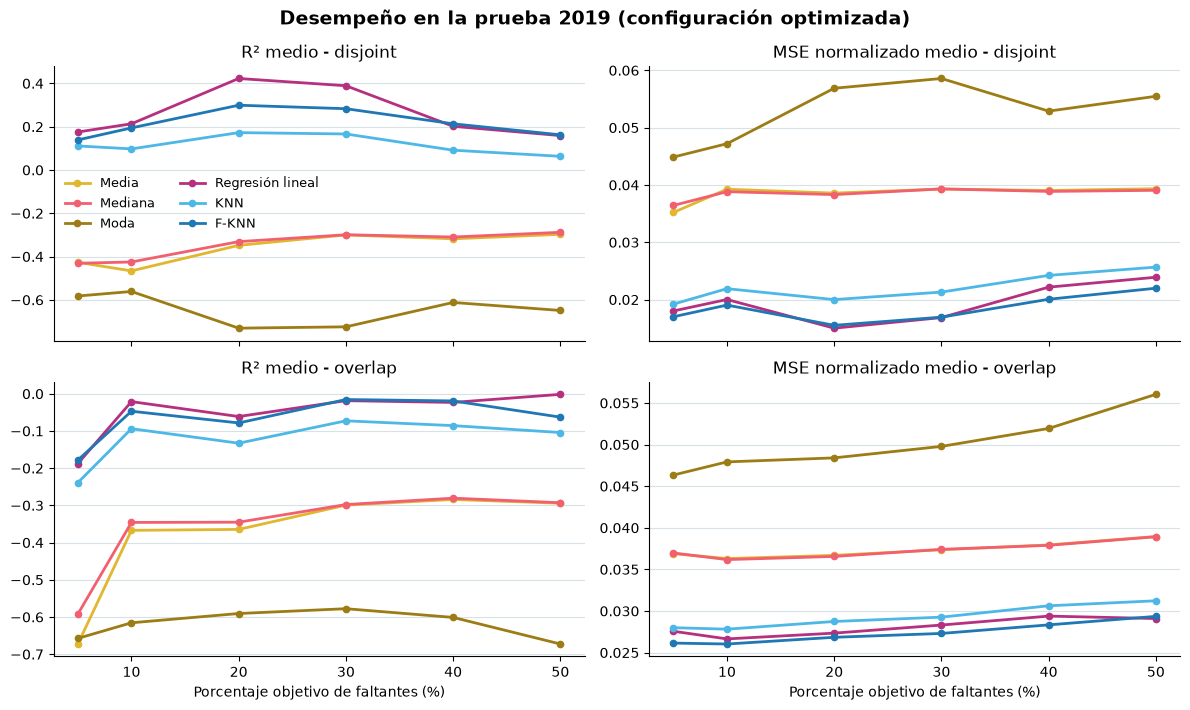

In [41]:
# ===== 9. RESULTADOS FINALES ORGANIZADOS (tablas, figuras y configuración) =====
import json
FIGS = Path("../figs")
FIGS.mkdir(exist_ok=True)


def resumen_final(df, pct_min=0):
    d = df[(df["pct_objetivo"] >= pct_min) & (df["pct_objetivo"] <= 50)].copy()
    d["modelo"] = pd.Categorical(d["modelo"], ORDEN_MODELOS, ordered=True)
    return (d.groupby(["patron", "modelo"], observed=True)
              .agg(escenarios=("R2", "size"), R2_medio=("R2", "mean"), R2_sd=("R2", "std"),
                   R2_min=("R2", "min"), MSE_medio=("MSE", "mean")).round(4))


def r2_mse_por_porcentaje(df):
    d = df[df["pct_objetivo"] <= 50].copy()
    d["modelo"] = pd.Categorical(d["modelo"], ORDEN_MODELOS, ordered=True)
    t = d.groupby(["patron", "pct_objetivo", "modelo"], observed=True)[["R2", "MSE"]].mean().round(4)
    return t.unstack("modelo")


def grafica_desempeno(df, titulo, archivo):
    colores = {"Media": "#E0B72F", "Mediana": "#F25F6F", "Moda": "#9C7C14",
               "Regresión lineal": "#B5307F", "KNN": "#4DB8E6", "F-KNN": "#1F77B4"}
    fig, ejes = plt.subplots(2, 2, figsize=(12, 7.2), sharex=True)
    for fila, patron in enumerate(["disjoint", "overlap"]):
        for col, (metrica, etiqueta) in enumerate([("R2", "R² medio"), ("MSE", "MSE normalizado medio")]):
            ax = ejes[fila, col]
            for modelo in ORDEN_MODELOS:
                d = df[(df["patron"] == patron) & (df["modelo"] == modelo) & (df["pct_objetivo"] <= 50)]
                curva = d.groupby("pct_objetivo")[metrica].mean().sort_index()
                ax.plot(curva.index, curva.values, marker="o", markersize=4.5, linewidth=2,
                        color=colores[modelo], label=modelo)
            ax.set_title(f"{etiqueta} - {patron}")
            ax.grid(axis="y", color="#D9E1E8", linewidth=0.8)
            ax.spines[["top", "right"]].set_visible(False)
            if fila == 1:
                ax.set_xlabel("Porcentaje objetivo de faltantes (%)")
    ejes[0, 0].legend(frameon=False, ncol=2, fontsize=9)
    fig.suptitle(titulo, fontsize=14, fontweight="semibold")
    fig.tight_layout()
    fig.savefig(FIGS / archivo, dpi=200, bbox_inches="tight")
    plt.show()


for nombre, df, titulo in [("validacion_2018", res_val_opt, "Desempeño en validación 2018 (configuración optimizada)"),
                           ("prueba_2019", res_test_opt, "Desempeño en la prueba 2019 (configuración optimizada)")]:
    print(f"\n=== {titulo}: todos los porcentajes ===")
    tabla = resumen_final(df)
    display(tabla)
    tabla.to_csv(RESULTADOS_DIR / f"tabla_{nombre}_optimizado.csv")
    print(f"=== {titulo}: 10 % a 50 % (sin el 5 %, donde el R² es inestable) ===")
    display(resumen_final(df, pct_min=10))
    r2_mse_por_porcentaje(df).to_csv(RESULTADOS_DIR / f"tabla_{nombre}_por_porcentaje.csv")
    grafica_desempeno(df, titulo, f"fig_{nombre}_optimizado.png")

### 9.2 Tipos de error: duración del bloque

In [42]:
# Tipos de error del modelo final: duración del bloque y patrón (prueba 2019)
ff = res_test_opt[(res_test_opt["modelo"] == "F-KNN") & (res_test_opt["pct_objetivo"] <= 50)]
orden_dur = ["1h", "6h", "1d", "3d", "7d"]
error_por_duracion = (ff.groupby(["patron", "duracion"])
                        .agg(escenarios=("R2", "size"), R2_medio=("R2", "mean"), MSE_medio=("MSE", "mean"))
                        .round(4).reset_index())
error_por_duracion["duracion"] = pd.Categorical(error_por_duracion["duracion"], orden_dur, ordered=True)
error_por_duracion = error_por_duracion.sort_values(["patron", "duracion"])
display(error_por_duracion)
error_por_duracion.to_csv(RESULTADOS_DIR / "fknn_error_por_duracion_prueba.csv", index=False)

,patron,duracion,escenarios,R2_medio,MSE_medio
1,disjoint,1h,140,0.5251,0.0113
3,disjoint,6h,160,0.1896,0.0184
0,disjoint,1d,160,0.1269,0.0205
2,disjoint,3d,120,0.1358,0.0201
4,disjoint,7d,100,0.0999,0.0199
6,overlap,1h,110,0.0798,0.0259
8,overlap,6h,120,-0.0688,0.0289
5,overlap,1d,120,-0.1422,0.0296
7,overlap,3d,80,-0.0505,0.0258
9,overlap,7d,60,-0.1975,0.0240


### 9.3 Configuración definitiva
Se guarda `config_modelo_final.json` (configuraciones, variables, rangos de 2018 y métricas de prueba) para el despliegue y el informe.

In [43]:
# Configuración definitiva (queda guardada para el despliegue y el informe)
X2018 = np.vstack([matriz("ajuste"), matriz("validacion")])
config_final = {
    "modelo_final": NOMBRE_FKNN_FINAL,
    "configuraciones": MODELOS_FINALES_OPT,
    "variables": variables,
    "minimo_2018": np.nanmin(X2018, axis=0).tolist(),
    "maximo_2018": np.nanmax(X2018, axis=0).tolist(),
    "grupos_sensores": CV_GRUPOS,
    "semilla_busqueda": SEMILLA_BUSQUEDA,
    "metricas_prueba_2019": {
        patron: {"R2_medio": float(g["R2"].mean()), "MSE_medio": float(g["MSE"].mean())}
        for patron, g in ff.groupby("patron")
    },
}
with open(RESULTADOS_DIR / "config_modelo_final.json", "w", encoding="utf-8") as f:
    json.dump(config_final, f, ensure_ascii=False, indent=2)
print("Guardado:", RESULTADOS_DIR / "config_modelo_final.json")

Guardado: ../data/gold/resultados_modelos/config_modelo_final.json


## 10. Interpretación: qué sensores se reconstruyen mejor
Desempeño por equipo de medición y por variable en la prueba 2019 (con al menos 20 % de faltantes). Sirve para traducir los resultados al lenguaje del problema: qué variables dependen de sus correlatos y cuáles no.

In [44]:
# ===== 10. INTERPRETACIÓN: ¿QUÉ SENSORES SE RECONSTRUYEN MEJOR? (prueba 2019) =====
# Usa evaluar_detalle, definida en la celda del análisis por equipo de medición.
PCT_MIN_DETALLE = 20    # con 5-10 % el R² por variable es muy inestable
det_test = pd.concat(
    [evaluar_detalle(n, IDS_TRAIN_FINAL, "evaluacion")
     for n in ["Media", MODELOS_FINALES_OPT["KNN"], MODELOS_FINALES_OPT["F-KNN"]]],
    ignore_index=True)
det_test["modelo"] = det_test["metodo"].map(ETIQUETAS)
guardar_resultados(det_test, "detalle_por_variable_prueba_2019")

d = det_test[det_test["pct_objetivo"] >= PCT_MIN_DETALLE]
por_equipo = d.groupby(["equipo", "modelo"]).agg(R2=("R2", "mean"), sse=("sse_norm", "sum"), n=("n_celdas", "sum"))
por_equipo["MSE"] = por_equipo["sse"] / por_equipo["n"]
tabla_equipo = por_equipo[["R2", "MSE"]].unstack("modelo").round(4)
display(tabla_equipo)
tabla_equipo.to_csv(RESULTADOS_DIR / "prueba_2019_por_equipo.csv")

por_variable = (d[d["modelo"] == "F-KNN"].groupby(["equipo", "variable"])
                  .agg(R2=("R2", "mean"), n=("n_celdas", "sum")).round(4))
display(por_variable)
por_variable.to_csv(RESULTADOS_DIR / "prueba_2019_fknn_por_variable.csv")

Guardado: ../data/gold/resultados_modelos/detalle_por_variable_prueba_2019.csv | filas: 25278


R2                     MSE                
modelo            F-KNN     KNN   Media   F-KNN     KNN   Media
equipo                                                         
anemometro       0.1952  0.1981 -0.0407  0.0152  0.0152  0.0204
barometro       -0.7326 -0.8234 -0.9941  0.0523  0.0544  0.0599
interior         0.0241 -0.0493 -0.5228  0.0272  0.0295  0.0446
luz              0.2905  0.3067 -0.0048  0.0205  0.0199  0.0302
pluviometro     -0.0212  0.0070 -0.0063  0.0136  0.0132  0.0134
termohigrometro  0.1704  0.0090 -0.3365  0.0208  0.0268  0.0442

R2       n
equipo          variable                               
anemometro      Gust(km/h)               0.2022  392433
                Wind Speed(km/h)         0.1882  392433
barometro       Absolute Pressure(hpa)  -0.7326  396430
interior        Indoor Humidity(%)      -0.2908  382507
                Indoor Temperature(°C)   0.3390  382507
luz             Light(lux)               0.2905  364431
pluviometro     Hour Rainfall(mm)       -0.0212  364464
termohigrometro DewPoint(°C)            -0.9355  591161
                Outdoor Humidity(%)      0.4731  591161
                Outdoor Temperature(°C)  0.5757  591161
                WindChill(°C)            0.5683  591161

## 11. Comparativa global del modelo ganador (F-KNN): Ajuste vs. Validación vs. Prueba

Comparación del desempeño del modelo final (**F-KNN**) a lo largo de las tres etapas metodológicas:
1. **Ajuste (CV 2018):** Promedio de la validación cruzada temporal expansiva (confirmación con 10 semillas).
2. **Validación (2018):** Evaluación del modelo ajustado con `ajuste` sobre el bloque posterior de 2018.
3. **Prueba (2019):** Evaluación final del modelo reentrenado con todo 2018 (`ajuste` + `validacion`) sobre el año 2019.


Resumen de desempeño de F-KNN a lo largo de las etapas:


R2_medio  MSE_medio
patron   tramo                                 
disjoint Ajuste (CV 2018)     0.3556     0.0231
         Prueba (2019)        0.2152     0.0184
         Validación (2018)    0.2872     0.0133
overlap  Ajuste (CV 2018)     0.0273     0.0348
         Prueba (2019)       -0.0669     0.0273
         Validación (2018)   -0.3623     0.0218

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


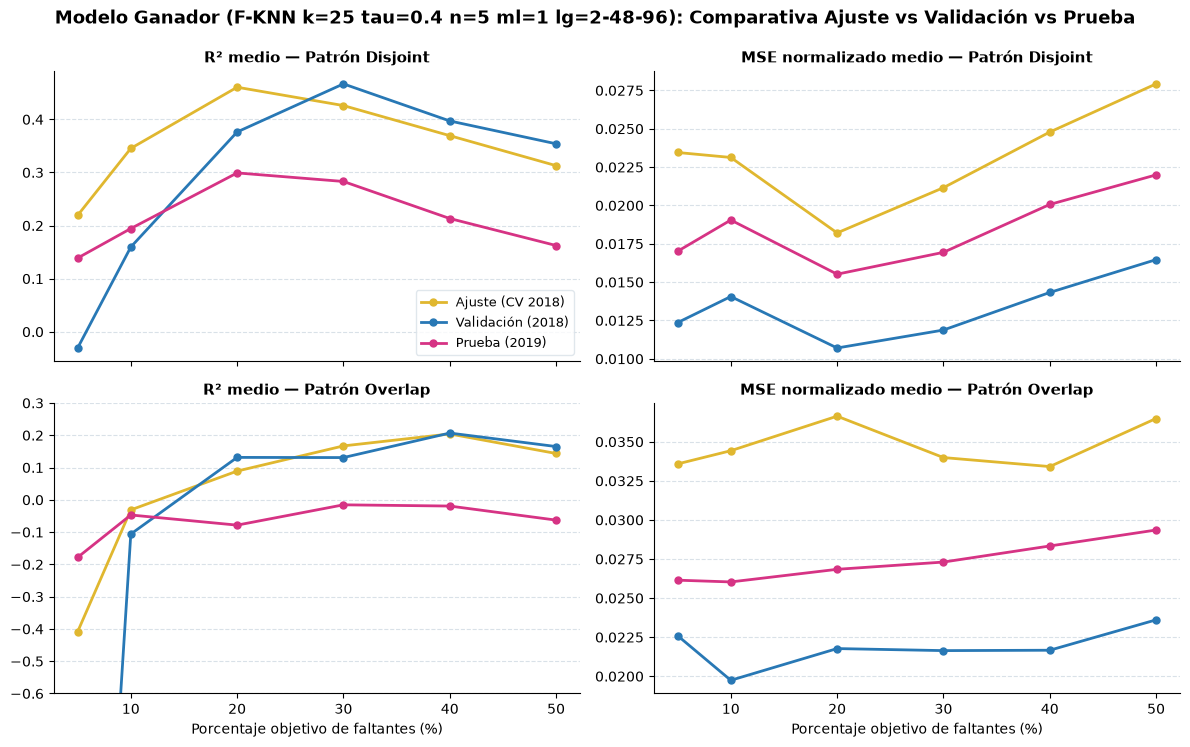

In [3]:
# ===== 11. COMPARATIVA GLOBAL F-KNN: AJUSTE vs VALIDACIÓN vs PRUEBA =====
# Esta celda es 100 % autónoma: lee los CSVs ya calculados y NO requiere correr todo el cuaderno.
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Rutas relativas estándar del proyecto
RESULTADOS_DIR = globals().get('RESULTADOS_DIR', Path('../data/gold/resultados_modelos'))
FIGS = globals().get('FIGS', Path('../figs'))
FIGS.mkdir(exist_ok=True)

NOMBRE_FKNN = globals().get('NOMBRE_FKNN_FINAL', 'F-KNN k=25 tau=0.4 n=5 ml=1 lg=2-48-96')

# 1. Ajuste (CV temporal en 2018)
if 'cv_fknn_confirmacion' in globals():
    df_cv = cv_fknn_confirmacion
else:
    df_cv = pd.read_csv(RESULTADOS_DIR / 'busqueda_fknn_confirmacion_cv.csv')

cv_fknn_final = df_cv[(df_cv['metodo'] == NOMBRE_FKNN) & (df_cv['pct_objetivo'] <= 50)].copy()
res_cv = cv_fknn_final.groupby(['patron', 'pct_objetivo'])[['R2', 'MSE']].mean().reset_index()
res_cv['tramo'] = 'Ajuste (CV 2018)'

# 2. Validación (2018)
if 'res_val_opt' in globals():
    df_val = res_val_opt
else:
    df_val = pd.read_csv(RESULTADOS_DIR / 'validacion_2018_optimizado.csv')

val_fknn_final = df_val[(df_val['modelo'] == 'F-KNN') & (df_val['pct_objetivo'] <= 50)].copy()
res_val = val_fknn_final.groupby(['patron', 'pct_objetivo'])[['R2', 'MSE']].mean().reset_index()
res_val['tramo'] = 'Validación (2018)'

# 3. Prueba (2019)
if 'res_test_opt' in globals():
    df_test = res_test_opt
else:
    df_test = pd.read_csv(RESULTADOS_DIR / 'prueba_2019_optimizado.csv')

test_fknn_final = df_test[(df_test['modelo'] == 'F-KNN') & (df_test['pct_objetivo'] <= 50)].copy()
res_test = test_fknn_final.groupby(['patron', 'pct_objetivo'])[['R2', 'MSE']].mean().reset_index()
res_test['tramo'] = 'Prueba (2019)'

# Consolidar tramos
df_comparativa_fknn = pd.concat([res_cv, res_val, res_test], ignore_index=True)

# Tabla resumen
tabla_resumen_tramos = (
    df_comparativa_fknn.groupby(['patron', 'tramo'])
    .agg(R2_medio=('R2', 'mean'), MSE_medio=('MSE', 'mean'))
    .round(4))
print('Resumen de desempeño de F-KNN a lo largo de las etapas:')
display(tabla_resumen_tramos)

# Gráfica comparativa
colores_tramos = {
    'Ajuste (CV 2018)': '#E0B72F',
    'Validación (2018)': '#2878B5',
    'Prueba (2019)': '#D63384',}
tramos_orden = ['Ajuste (CV 2018)', 'Validación (2018)', 'Prueba (2019)']

fig, ejes = plt.subplots(2, 2, figsize=(12, 7.5), sharex=True)

for fila, patron in enumerate(['disjoint', 'overlap']):
    for col, (metrica, etiqueta) in enumerate([('R2', 'R² medio'), ('MSE', 'MSE normalizado medio')]):
        ax = ejes[fila, col]
        for tramo in tramos_orden:
            sub = df_comparativa_fknn[
                (df_comparativa_fknn['patron'] == patron) & (df_comparativa_fknn['tramo'] == tramo)
            ].sort_values('pct_objetivo')
            ax.plot(
                sub['pct_objetivo'], sub[metrica],
                marker='o', markersize=5, linewidth=2,
                color=colores_tramos[tramo], label=tramo
            )
        
        ax.set_title(f'{etiqueta} — Patrón {patron.capitalize()}', fontsize=11, fontweight='semibold')
        ax.grid(axis='y', color='#D9E1E8', linewidth=0.8, linestyle='--')
        ax.spines[['top', 'right']].set_visible(False)
        
        if metrica == 'R2' and patron == 'overlap':
            ax.set_ylim(-0.6, 0.3)
            
        if fila == 1:
            ax.set_xlabel('Porcentaje objetivo de faltantes (%)', fontsize=10)

ejes[0, 0].legend(frameon=True, facecolor='white', edgecolor='#D9E1E8', fontsize=9)
fig.suptitle(
    f'Modelo Ganador ({NOMBRE_FKNN}): Comparativa Ajuste vs Validación vs Prueba',
    fontsize=13, fontweight='bold', y=0.99
)
fig.tight_layout()
fig.savefig(FIGS / 'fig_fknn_comparativa_tramos.png', dpi=200, bbox_inches='tight')
plt.show()
